# Background aerosol, precursors and NOx: PD vs FUT

**Question.** What aerosol and ozone-precursor background do the PD and FUT runs see, and how different is it?

**How the background is set.** OsloAero aerosol is prognostic: the model computes it from emissions. What is *prescribed* is the emissions, plus the ocean DMS concentration and the SST. Each run repeats **one year** of every emission file (`CYCLICAL`):

| | PD (`NF2000…`, use case `2000_cam6_noresm_tropstratchem`) | FUT (`NF2100ssp585…`, use case `2100ssp585_cam6_noresm_tropstratchem`) |
|---|---|---|
| Anthropogenic, aircraft, biomass burning, tropospheric volcanic | CMIP6 historical (`cmip6_emissions_version20211124`, 1849–2015), **year 2000** | SSP5-8.5 REMIND-MAgPIE (`cmip6_emissions_version20230630`, 2014–2301), **year 2100** |
| Stratospheric volcanic | VolcanEESM v3.10 piControl, mean 1850–2014 (same file) | same file |
| Soil NOx/NH3, ocean CO/VOC ("other") | CMIP6 1750–2015, one year repeated | `emissions_ssp585_2deg`, one year repeated |
| Ocean DMS concentration | NorESM2 NHIST 1995–2005 climatology | NorESM2 SSP5-8.5 2090–2100 climatology |
| Sea salt, dust, MEGAN BVOC | online | online |
| Winds | nudged to PD met | same PD winds |

Biomass burning is **prescribed** in both periods (CMIP6 / SSP5-8.5 values), not interactive.

**What this notebook shows.**
1. The inputs, read from the resolved `CaseDocs/atm_in` of CTRL_PD `-20261029` and CTRL_FUT `-20261028` (new chain). The other runs of a period use the same use case.
2. Global emission totals of the year each run reads (2000 or 2100), by sector.
3. Maps PD, FUT, FUT − PD of the emissions.
4. Ocean DMS concentration (input).
5. What the model makes of it: AOD, sulfate burden, droplet number, surface SO₂, DMS, NOx, O₃, CO (CTRL_PD vs CTRL_FUT, 2001–2025).
6. Time series of the whole prescribed files, of which the runs read only one year.
7. Greenhouse-gas boundary condition (CH₄, N₂O, CO₂).
8. Online sources: MEGAN BVOC, dust, sea salt, ocean DMS flux, lightning NOx: global totals (bar chart, 2001–2025 mean) and yearly time series, as for the prescribed emissions.
9. Appendix: the same maps, global.

**Maps** show the **Arctic** (north of 45°N, polar view; dashed circle = Arctic Circle, 66.5°N). The global versions of every map are in the Appendix (files in `figures/appendix-global/`).

**Units.** Emissions in the files are molecules cm⁻² s⁻¹ (surface) or molecules cm⁻³ s⁻¹ (vertical). They are converted with the molar mass the model uses (`chem_mech.doc`): BC and OM count as **C (12.011 g/mol)** and SO4_PR as **H₂SO₄**, so masses are what the model receives. Vertical files are integrated over the layer thickness (`altitude_int`). Annual totals are weighted by days per month (noleap).

## What each compound does in this model

Checked in the model code of this setup (`CaseDocs/chem_mech.in` = `pp_tropstrat_mam_oslo`, OsloAero source in `~/NorESM2.3_beta01/components/cam/src/chemistry/oslo_aero/`) **(a)**, unless tagged.

| Group | Species read | What the model does with it |
|---|---|---|
| **SOx** | SO2, SO4_PR | SO₂ → sulfate in air (OH → H₂SO₄, which **nucleates new particles** or condenses on existing ones) and in cloud water (H₂O₂ and O₃; the O₃ path speeds up at higher cloud-water pH). SO4_PR = sulfate emitted as particles. Sulfate is the main source of cloud-droplet seeds (CCN) and the main anthropogenic cooling aerosol. |
| **BC** | BC_N, BC_AX (anthropogenic, aircraft), BC_NI (fires) | **Absorbs sunlight** (absorption AOD, warming above clouds). Grows into CCN once coated by sulfate/SOA. |
| **OM** | OM_NI (fires and anthropogenic) | Primary organic particles, internally mixed with BC. Scatter light, act as CCN, and give **surface for SOA** to condense on. Ocean OM (sea spray, from chlorophyll) is added online, see §9. |
| **NOx** | NO, NO2 | Controls **O₃ production and OH**, the main oxidant, so it sets how fast SO₂, DMS, isoprene and monoterpenes react. At night NO₃ oxidises DMS and monoterpenes. HNO₃ enters the cloud-water charge balance (lowers pH). **No nitrate aerosol** in OsloAero. |
| **NH3** | NH3 | **No ammonium aerosol tracer** (sulfate is assumed to be NH₄HSO₄, fixed). NH₃ is a gas: removed by OH (→ NHDEP) and **dissolved in cloud droplets**, where it **raises the pH** in the charge balance (`mo_setsox.F90`: `tmp_pos = xph + tmp_nh4`), which speeds up SO₂ + O₃ → sulfate. So the +48 % NH₃ in FUT can raise in-cloud sulfate production; the size of this effect is not quantified here (no pH or aqueous-production output). |
| **CO** | CO | OH sink (less oxidant, longer CH₄ lifetime), O₃ source. |
| **NMVOC** | 26 species | O₃/OH chemistry (formaldehyde, PAN, …). **None of the prescribed anthropogenic VOCs makes SOA.** Only ISOP (yield 0.025 SOA_SV), MTERP (0.15 SOA_LV/SV) and DMS make SOA precursors in this mechanism. ISOP and MTERP in the files are fire emissions; the large source is MEGAN (online, §9). |
| **DMS** | seawater concentration (+ a little from fires) | Flux computed online (wind, SST, open ocean). Oxidised by OH and NO₃ → **SO₂ → sulfate**; the OH path also gives **SOA precursors** (`DMS + OH → 0.5 SO₂ + 0.029 SOA_LV + 0.114 SOA_SV`). Main natural sulfur source; dominates CCN over remote oceans and the summer Arctic **(b, literature)**. |

**Not prescribed from files but part of the background (§8–9):** greenhouse gases at the surface (CH₄, N₂O, CO₂, CFCs), and the online sources MEGAN BVOC, dust, sea salt (+ ocean OM), ocean DMS flux, lightning NOx.

In [1]:
import os
os.environ.setdefault('HDF5_USE_FILE_LOCKING', 'FALSE')  # before netCDF4/xarray import
import re
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor
import numpy as np
import pandas as pd
import xarray as xr
import netCDF4
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.path as mpath
import cartopy.crs as ccrs

CASEDIR = Path.home() / 'cases/BRL_FRST_XPSN'
CASES = {'PD': 'NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029',
         'FUT': 'NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_f19-20261028'}
ALIAS = {'PD': 'CTRL_PD', 'FUT': 'CTRL_FUT'}
PROC = Path('../../data/processed-data/postprocessing')
PROC_YEARS = '2001-2025'
YEARS = list(range(int(PROC_YEARS[:4]), int(PROC_YEARS[-4:]) + 1))
YRS = f'{YEARS[0]}–{YEARS[-1]}'
DMS_DIR = Path('/cluster/shared/noresm/inputdata/noresm-only/atm/cam/camoslo')
OUT = Path('background_aerosol_pd_fut_outputs')
CACHE, FIG, TAB = OUT / 'cache', OUT / 'figures', OUT / 'tables'  # cache = regenerable totals and maps
FIG_GLOBAL = FIG / 'appendix-global'  # global maps (Appendix)
for d in (CACHE, FIG, TAB, FIG_GLOBAL):
    d.mkdir(parents=True, exist_ok=True)
REBUILD_CACHE = False
N_WORKERS = 8
LAT_MAP = 45      # Arctic maps: north of this latitude
APPENDIX = []     # map calls, replayed globally in the Appendix

NA, R_EARTH = 6.02214076e23, 6.371e6
DPM = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])  # noleap
# project palette, in order; gold = total; PD = navy, FUT = red
TEAL, NAVY, PLUM, RED, ORANGE, GOLD, GREY = '#5D9A92', '#2C3990', '#9A4A84', '#BC423E', '#DE7A3A', '#EBC45C', '#CCCCCC'
PCOL = {'PD': NAVY, 'FUT': RED}

# molar mass (g/mol) of each species as the model counts it (chem_mech.doc formula)
MW = dict(SO2=64.066, SO4_PR=98.079, BC_AX=12.011, BC_N=12.011, BC_NI=12.011, OM_NI=12.011,
          NO=30.006, NO2=46.006, CO=28.010, NH3=17.031, DMS=62.134, ISOP=68.117, MTERP=136.234,
          BENZENE=78.112, BIGALK=72.149, BIGENE=56.106, C2H2=26.037, C2H4=28.053, C2H5OH=46.068,
          C2H6=30.069, C3H6=42.080, C3H8=44.096, CH2O=30.026, CH3CHO=44.053, CH3CN=41.052,
          CH3COCH3=58.079, CH3COCHO=72.063, CH3COOH=60.052, CH3OH=32.042, GLYALD=60.052,
          HCN=27.025, HCOOH=46.025, MEK=72.106, TOLUENE=92.138, XYLENES=106.165)
VOCS = [s for s in MW if s not in ('SO2', 'SO4_PR', 'BC_AX', 'BC_N', 'BC_NI', 'OM_NI', 'NO', 'NO2', 'CO', 'NH3', 'DMS')]
S, N = 32.06, 14.007
GROUPS = {  # group -> {species: factor to the group unit}
    'SOx (Tg S)': {'SO2': S / MW['SO2'], 'SO4_PR': S / MW['SO4_PR']},
    'BC (Tg C)': {'BC_AX': 1, 'BC_N': 1, 'BC_NI': 1},
    'OM (Tg)': {'OM_NI': 1},
    'NOx (Tg N)': {'NO': N / MW['NO'], 'NO2': N / MW['NO2']},
    'NH3 (Tg)': {'NH3': 1},
    'CO (Tg)': {'CO': 1},
    'NMVOC (Tg)': {s: 1 for s in VOCS},
}
SECTORS = ['anthropogenic, surface', 'anthropogenic, elevated', 'aircraft', 'biomass burning',
           'volcanic, tropospheric', 'volcanic, stratospheric', 'natural (soil / ocean)']
SCOL = dict(zip(SECTORS, [TEAL, NAVY, PLUM, RED, ORANGE, ORANGE, GREY]))

## 1. Inputs, from the resolved namelists

Each entry of `srf_emis_specifier` (surface) and `ext_frc_specifier` (3-D) is one file. A factor in front of the path (e.g. `0.9*`) scales it: the stratospheric volcanic SO₂ goes 90 % to SO2 and 10 % to SO4_PR. E90 is an idealised tracer and is skipped.

In [2]:
def sector(path):
    n = Path(path).name
    for key, lab in [('Volcan', 'volcanic, stratospheric'), ('_anthrosurf', 'anthropogenic, surface'),
                     ('_anthroprof', 'anthropogenic, elevated'), ('_air', 'aircraft'), ('_bb', 'biomass burning'),
                     ('_volc', 'volcanic, tropospheric'), ('_other_', 'natural (soil / ocean)')]:
        if key in n:
            return lab
    raise ValueError(n)

def read_inputs(period):
    txt = (CASEDIR / CASES[period] / 'CaseDocs/atm_in').read_text()
    cyc = {k: int(re.search(rf'{k}\s*=\s*(\d+)', txt).group(1)) for k in ('srf_emis_cycle_yr', 'ext_frc_cycle_yr')}
    assert len(set(cyc.values())) == 1, cyc
    for k in ('srf_emis_type', 'ext_frc_type'):
        assert re.search(rf"{k}\s*=\s*'CYCLICAL'", txt), k
    rows = []
    for key in ('srf_emis_specifier', 'ext_frc_specifier'):
        block = re.search(rf'{key}\s*=\s*(.*?)\n\s*\w+\s*=', txt, re.S).group(1)
        for item in re.findall(r"'([^']*)'", block):
            sp, rhs = [s.strip() for s in item.split('->')]
            if sp == 'E90':  # idealised tracer
                continue
            m = re.match(r'(?:([0-9.]+)\*)?(\S+)', rhs)
            rows.append(dict(period=period, species=sp, sector=sector(m.group(2)), scale=float(m.group(1) or 1),
                             namelist=key, path=m.group(2)))
    return pd.DataFrame(rows), cyc['srf_emis_cycle_yr']

INPUTS, CYCLE = [], {}
for p in CASES:
    df, CYCLE[p] = read_inputs(p)
    INPUTS.append(df)
INPUTS = pd.concat(INPUTS, ignore_index=True)
assert not INPUTS.duplicated(['period', 'species', 'sector']).any()
assert set(INPUTS.species) <= set(MW), set(INPUTS.species) - set(MW)
print('cycle year:', CYCLE)
print('files per period:', INPUTS.groupby('period').size().to_dict())
shared = set(INPUTS.query('period == "PD"').path) & set(INPUTS.query('period == "FUT"').path)
print('files used by both periods:', [Path(f).name for f in shared])
with pd.option_context('display.max_colwidth', 90, 'display.max_rows', 200):
    tab = INPUTS.assign(file=INPUTS.path.map(lambda f: Path(f).name)).pivot_table(
        index=['species', 'sector'], columns='period', values='file', aggfunc='first')[['PD', 'FUT']]
    tab.to_csv(TAB / 'input_files.csv')
    display(tab)

cycle year: {'PD': 2000, 'FUT': 2100}
files per period: {'FUT': 83, 'PD': 83}
files used by both periods: ['VolcanEESMv3.10_piControl_SO2_1850-2014average_date_2000_2100_2deg_ZeroTrop_c190701.nc']


period                                                                                                                   PD  \
species  sector                                                                                                               
BC_AX    aircraft                        emissions_cmip6_noresm2_BC_AX_airALL_vertical_1849-2015_1.9x2.5_version20211124.nc   
         anthropogenic, elevated  emissions_cmip6_noresm2_BC_AX_anthroprofALL_vertical_1849-2015_1.9x2.5_version20211124.nc   
         anthropogenic, surface    emissions_cmip6_noresm2_BC_AX_anthrosurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
BC_N     aircraft                         emissions_cmip6_noresm2_BC_N_airALL_vertical_1849-2015_1.9x2.5_version20211124.nc   
         anthropogenic, elevated   emissions_cmip6_noresm2_BC_N_anthroprofALL_vertical_1849-2015_1.9x2.5_version20211124.nc   
         anthropogenic, surface     emissions_cmip6_noresm2_BC_N_anthrosurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
BC_NI    biomass burning                  emissions_cmip6_noresm2_BC_NI_bbALL_vertical_1849-2015_1.9x2.5_version20211124.nc   
BENZENE  anthropogenic, surface   emissions_cmip6_noresm2_BENZENE_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021...   
         biomass burning             emissions_cmip6_noresm2_BENZENE_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
BIGALK   anthropogenic, surface   emissions_cmip6_noresm2_BIGALK_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version20211...   
         biomass burning              emissions_cmip6_noresm2_BIGALK_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
BIGENE   anthropogenic, surface   emissions_cmip6_noresm2_BIGENE_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version20211...   
         biomass burning              emissions_cmip6_noresm2_BIGENE_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
C2H2     anthropogenic, surface   emissions_cmip6_noresm2_C2H2_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021112...   
         biomass burning                emissions_cmip6_noresm2_C2H2_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
C2H4     anthropogenic, surface   emissions_cmip6_noresm2_C2H4_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021112...   
         biomass burning                emissions_cmip6_noresm2_C2H4_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
         natural (soil / ocean)                           emissions-cmip6_C2H4_other_surface_1750-2015_1.9x2.5_c20170322.nc   
C2H5OH   anthropogenic, surface   emissions_cmip6_noresm2_C2H5OH_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version20211...   
         biomass burning              emissions_cmip6_noresm2_C2H5OH_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
C2H6     anthropogenic, surface   emissions_cmip6_noresm2_C2H6_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021112...   
         biomass burning                emissions_cmip6_noresm2_C2H6_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
         natural (soil / ocean)                           emissions-cmip6_C2H6_other_surface_1750-2015_1.9x2.5_c20170322.nc   
C3H6     anthropogenic, surface   emissions_cmip6_noresm2_C3H6_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021112...   
         biomass burning                emissions_cmip6_noresm2_C3H6_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
         natural (soil / ocean)                           emissions-cmip6_C3H6_other_surface_1750-2015_1.9x2.5_c20170322.nc   
C3H8     anthropogenic, surface   emissions_cmip6_noresm2_C3H8_anthrosurfgasALL_surface_1849-2015_1.9x2.5_version2021112...   
         biomass burning                emissions_cmip6_noresm2_C3H8_bbsurfALL_surface_1849-2015_1.9x2.5_version20211124.nc   
         natural (soil / ocean)                           emissions-cmip6_C3H8_other_surface_1750-2015_1.9x2.5_c20170322.nc   
CH2O     anthropogenic, surface   emissions_cmip6_noresm2_CH2O_

## 2. Read every file once

For each file: the global total of every month in the file (→ annual totals, for the time series of §6) and the annual map of the cycle year (§3). The cycle year must have 12 months in the file. Years with fewer than 12 months (first/last of a file) are dropped from the totals. Results are cached in `cache/`; reading all files (~40 GB) takes several minutes.

In [3]:
def cell_area(lat, nlon):
    lat = np.asarray(lat, float)
    edges = np.clip(np.concatenate([[-90], 0.5 * (lat[1:] + lat[:-1]), [90]]), -90, 90)
    band = R_EARTH**2 * np.deg2rad(360 / nlon) * np.diff(np.sin(np.deg2rad(edges)))
    return np.repeat(band[:, None], nlon, axis=1)  # m2

def read_file(args):
    path, species, scale, cycle_year = args
    with netCDF4.Dataset(path) as d:
        date = np.asarray(d['date'][:]).astype(int)
        names = [v for v, x in d.variables.items() if {'time', 'lat', 'lon'} <= set(x.dimensions)]
        vertical = 'altitude_int' in d.dimensions
        dz = np.diff(np.asarray(d['altitude_int'][:], float)) * 1e5 if vertical else None  # km -> cm
        lat, lon = np.asarray(d['lat'][:], float), np.asarray(d['lon'][:], float)
        area = cell_area(lat, len(lon))
        conv = scale * 1e4 / NA * MW[species] * 1e-3  # molecules cm-2 s-1 -> kg m-2 s-1
        tot, cmap, ncyc = np.zeros(len(date)), np.zeros(area.shape), 0
        for i0 in range(0, len(date), 12):
            sl = slice(i0, min(i0 + 12, len(date)))
            col = 0.
            for v in names:
                x = np.nan_to_num(np.ma.filled(d[v][sl].astype('f8'), 0.))
                col = col + (np.tensordot(x, dz, axes=([1], [0])) if vertical else x)
            flux = col * conv
            tot[sl] = (flux * area).sum((1, 2))  # kg s-1
            for k, dt in enumerate(date[sl]):
                if dt // 10000 == cycle_year:
                    cmap += flux[k] * DPM[dt // 100 % 100 - 1] * 86400
                    ncyc += 1
    assert ncyc == 12, (path, ncyc)
    mon = date // 100 % 100
    g = pd.DataFrame(dict(year=date // 10000, kg=tot * DPM[mon - 1] * 86400)).groupby('year').kg.agg(['sum', 'size'])
    annual = g['sum'][g['size'] == 12] / 1e9  # Tg yr-1
    return dict(annual=annual, map=cmap, lat=lat, lon=lon, vertical=vertical, vars=','.join(names))

f_tot, f_map = CACHE / 'annual_totals.csv', CACHE / 'cycle_year_maps.nc'
if f_tot.is_file() and f_map.is_file() and not REBUILD_CACHE:
    TOT = pd.read_csv(f_tot)
    MAPS = xr.open_dataarray(f_map).load()
else:
    args = [(r.path, r.species, r.scale, CYCLE[r.period]) for r in INPUTS.itertuples()]
    with ProcessPoolExecutor(N_WORKERS) as ex:
        res = list(ex.map(read_file, args))
    TOT = pd.concat([pd.DataFrame(dict(period=r.period, species=r.species, sector=r.sector, year=o['annual'].index,
                                       Tg=o['annual'].values, vertical=o['vertical'], vars=o['vars']))
                     for r, o in zip(INPUTS.itertuples(), res)], ignore_index=True)
    lat0, lon0 = res[0]['lat'], res[0]['lon']
    assert all(np.allclose(o['lat'], lat0) and np.allclose(o['lon'], lon0) for o in res)
    MAPS = xr.DataArray(np.stack([o['map'] for o in res]), dims=('entry', 'lat', 'lon'),
                        coords=dict(lat=lat0, lon=lon0, **{c: ('entry', INPUTS[c].to_numpy(dtype=str))  # numpy str, not pandas StringDtype
                                                       for c in ('period', 'species', 'sector')}),
                        name='emission', attrs=dict(units='kg m-2 yr-1', note='cycle year, column-integrated'))
    TOT.to_csv(f_tot, index=False)
    MAPS.to_netcdf(f_map)
AREA = xr.DataArray(cell_area(MAPS.lat, MAPS.lon.size), dims=('lat', 'lon'), coords=dict(lat=MAPS.lat, lon=MAPS.lon))
assert abs(AREA.sum() / (4 * np.pi * R_EARTH**2) - 1) < 1e-6
# check: map of the cycle year integrates to the annual total
chk = (MAPS * AREA).sum(('lat', 'lon')).values / 1e9
tot_i = TOT.set_index(['period', 'species', 'sector', 'year']).Tg
ref = [tot_i[(r.period, r.species, r.sector, CYCLE[r.period])] for r in INPUTS.itertuples()]
assert np.allclose(chk, ref, rtol=1e-6)
print(TOT.groupby(['period', 'vertical']).species.nunique())

period  vertical
FUT     False       33
        True         8
PD      False       33
        True         8
Name: species, dtype: int64


## 3. Global totals of the year each run reads

PD = year 2000 of the PD files, FUT = year 2100 of the FUT files. Groups: SOx = SO2 + primary SO4 (Tg S); BC = BC_AX + BC_N + BC_NI; NOx = NO + NO2 (Tg N); NMVOC = sum of the prescribed VOC species (anthropogenic, biomass burning and ocean; MEGAN emissions are online and not included).

In [4]:
cyc = TOT[TOT.year == TOT.period.map(CYCLE)]
rows = []
for g, mem in GROUPS.items():
    sub = cyc[cyc.species.isin(list(mem))]
    val = (sub.Tg * sub.species.map(mem)).groupby([sub.period, sub.sector]).sum()
    for (p, s), v in val.items():
        rows.append(dict(group=g, period=p, sector=s, value=v))
BYSEC = pd.DataFrame(rows).pivot_table(index=['group', 'sector'], columns='period', values='value', fill_value=0)[['PD', 'FUT']]
TOTAL = BYSEC.groupby(level='group', sort=False).sum().loc[list(GROUPS)]
for t in (BYSEC, TOTAL):
    t['FUT − PD'] = t.FUT - t.PD
    t['FUT / PD'] = t.FUT / t.PD.where(t.PD != 0)
TOTAL.to_csv(TAB / 'emission_totals_cycle_year.csv')
BYSEC.to_csv(TAB / 'emission_totals_cycle_year_by_sector.csv')
with pd.option_context('display.float_format', '{:.3g}'.format):
    display(TOTAL)
    display(BYSEC)

period,PD,FUT,FUT − PD,FUT / PD
group,,,,
SOx (Tg S),70.6,29.7,-40.9,0.421
BC (Tg C),7.47,3.32,-4.15,0.444
OM (Tg),55.4,42.1,-13.3,0.76
NOx (Tg N),48.4,37.4,-11,0.773
NH3 (Tg),57,84.2,27.2,1.48
CO (Tg),908,598,-310,0.658
NMVOC (Tg),197,164,-33.1,0.832


period                                  PD     FUT  FUT − PD  FUT / PD
group      sector                                                     
BC (Tg C)  aircraft                0.00899  0.0231    0.0141      2.57
           anthropogenic, elevated    1.24   0.479    -0.759     0.387
           anthropogenic, surface     4.57    1.16     -3.41     0.254
           biomass burning            1.65    1.66   0.00466         1
CO (Tg)    aircraft                  0.528   0.578    0.0493      1.09
           anthropogenic, surface      599     239      -360     0.399
           biomass burning             289     338      49.4      1.17
           natural (soil / ocean)     19.9    19.9         0         1
NH3 (Tg)   anthropogenic, surface     51.2    77.6      26.3      1.51
           biomass burning            3.41    4.24     0.831      1.24
           natural (soil / ocean)     2.35    2.35         0         1
NMVOC (Tg) anthropogenic, surface      138    99.2     -39.2     0.717
           biomass burning            53.6    59.7      6.11      1.11
           natural (soil / ocean)     5.19    5.19         0         1
NOx (Tg N) aircraft                  0.801    3.13      2.33      3.91
           anthropogenic, surface     36.4    22.5     -13.9     0.618
           biomass burning            6.28    6.89     0.606       1.1
           natural (soil / ocean)     4.95    4.95         0         1
OM (Tg)    aircraft                0.00621 0.00737   0.00116      1.19
           anthropogenic, elevated    2.89    1.26     -1.63     0.436
           anthropogenic, surface     17.6    3.15     -14.4     0.179
           biomass burning            34.9    37.7      2.76      1.08
SOx (Tg S) aircraft                   0.12   0.142    0.0224      1.19
           anthropogenic, elevated    44.6    11.6       -33      0.26
           anthropogenic, surface     9.92    2.03     -7.89     0.205
           biomass burning            1.01       1  -0.00817     0.992
           volcanic, stratospheric   0.296   0.296         0         1
           volcanic, tropospheric     14.6    14.6         0         1

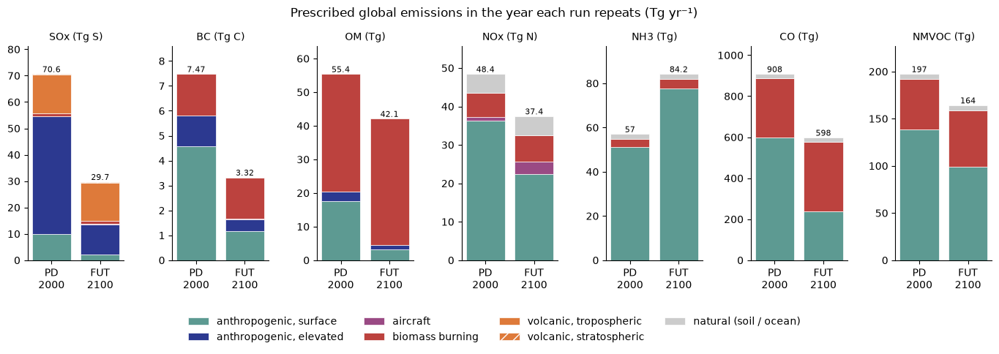

In [5]:
fig, axs = plt.subplots(1, len(GROUPS), figsize=(17, 3.8), gridspec_kw=dict(wspace=0.5))
for ax, g in zip(axs, GROUPS):
    sub = BYSEC.loc[g]
    bottom = np.zeros(2)
    for s in SECTORS:
        if s in sub.index:
            v = sub.loc[s, ['PD', 'FUT']].values
            ax.bar([0, 1], v, bottom=bottom, color=SCOL[s], edgecolor='white', lw=0.5,
                   hatch='//' if s == 'volcanic, stratospheric' else None, label=s)
            bottom += v
    for x, v in enumerate(bottom):
        ax.text(x, v, f'{float(f"{v:.3g}"):g}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks([0, 1], [f'PD\n{CYCLE["PD"]}', f'FUT\n{CYCLE["FUT"]}'])
    ax.set_title(g, fontsize=10)
    ax.set_ylim(0, bottom.max() * 1.15)
    ax.spines[['top', 'right']].set_visible(False)
h, l = [], []
for ax in axs:
    for hh, ll in zip(*ax.get_legend_handles_labels()):
        if ll not in l:
            h.append(hh); l.append(ll)
fig.legend(h, l, loc='upper center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Prescribed global emissions in the year each run repeats (Tg yr⁻¹)', y=1.02)
fig.savefig(FIG / 'emission_totals_cycle_year.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Emission maps: PD, FUT, FUT − PD (Arctic; global in the Appendix)

Column-integrated, all sectors, g m⁻² yr⁻¹ (SOx in g S, NOx in g N). Absolute maps on a log scale; the difference on a symmetric log-spaced scale (RdBu_r, red = more in FUT). Cells below the lowest level are white.

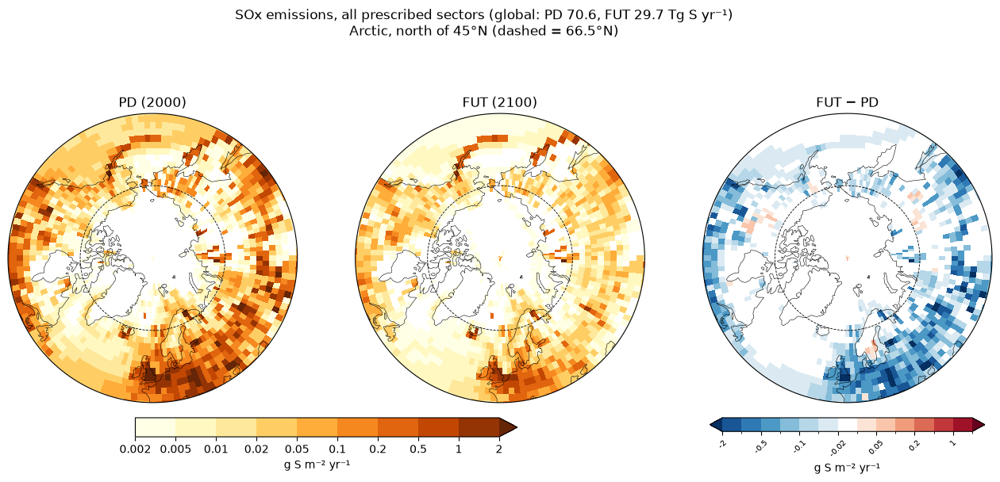

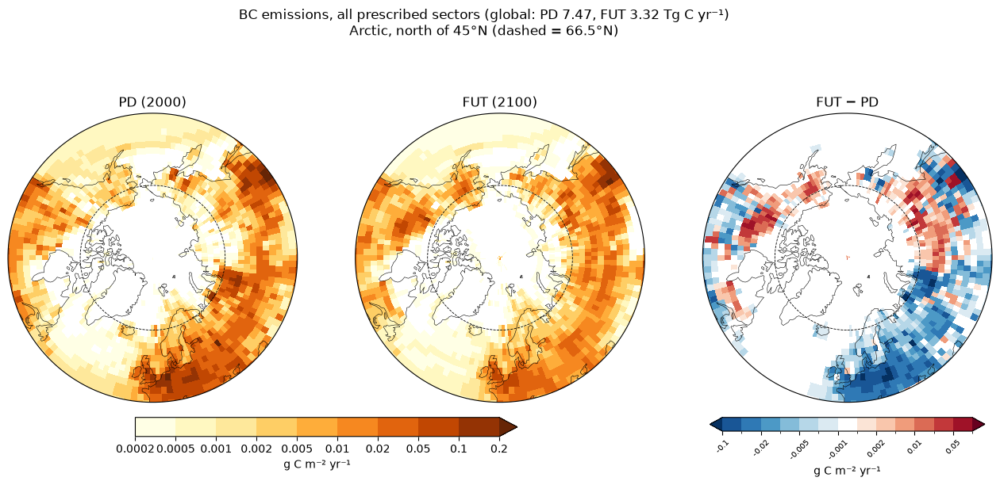

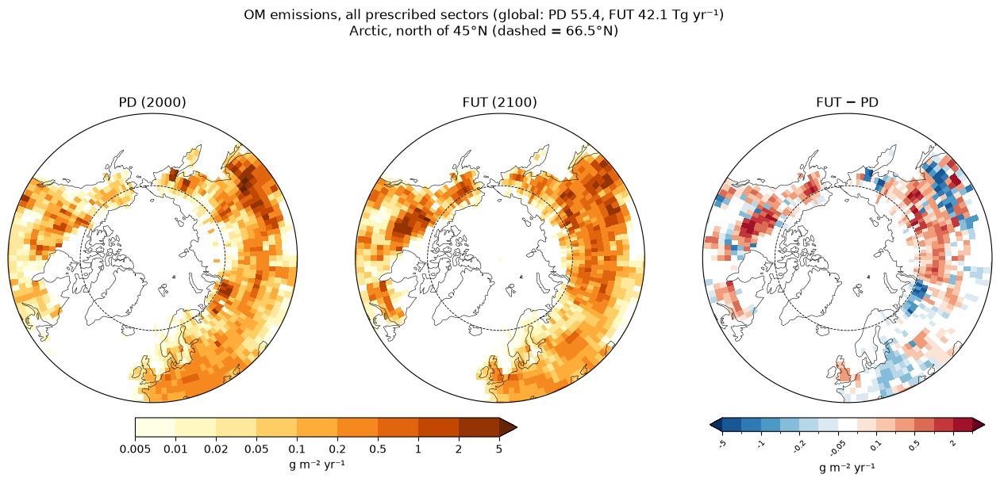

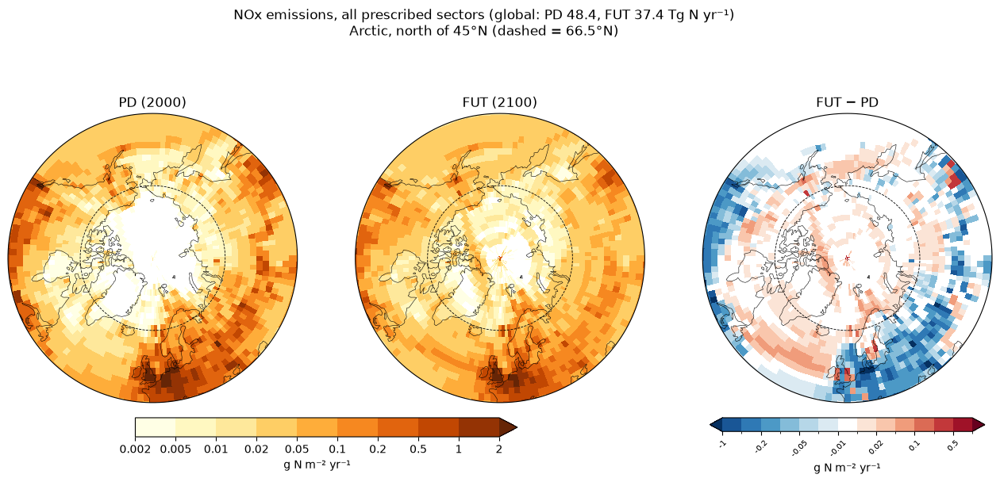

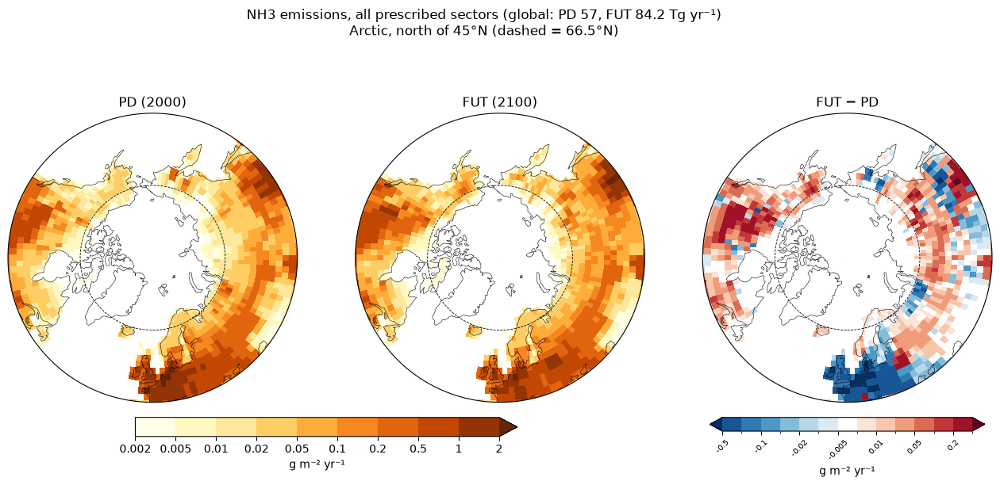

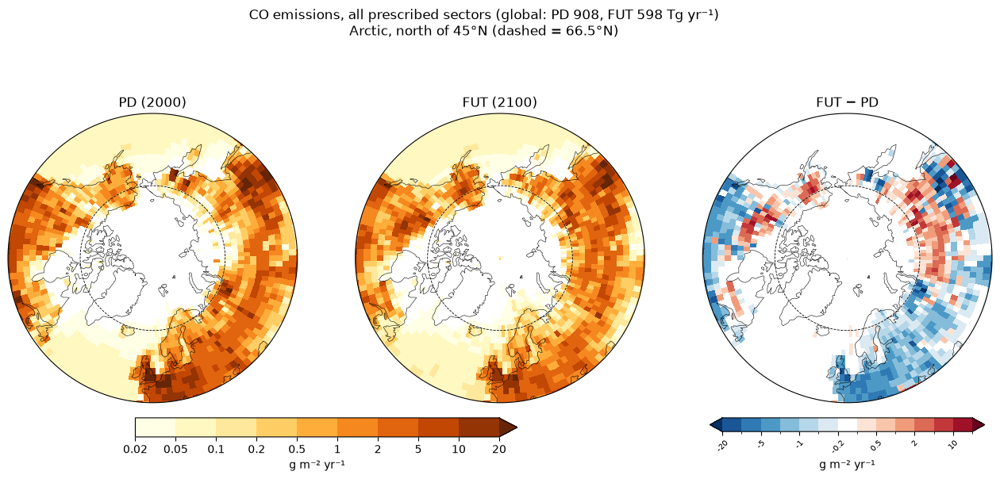

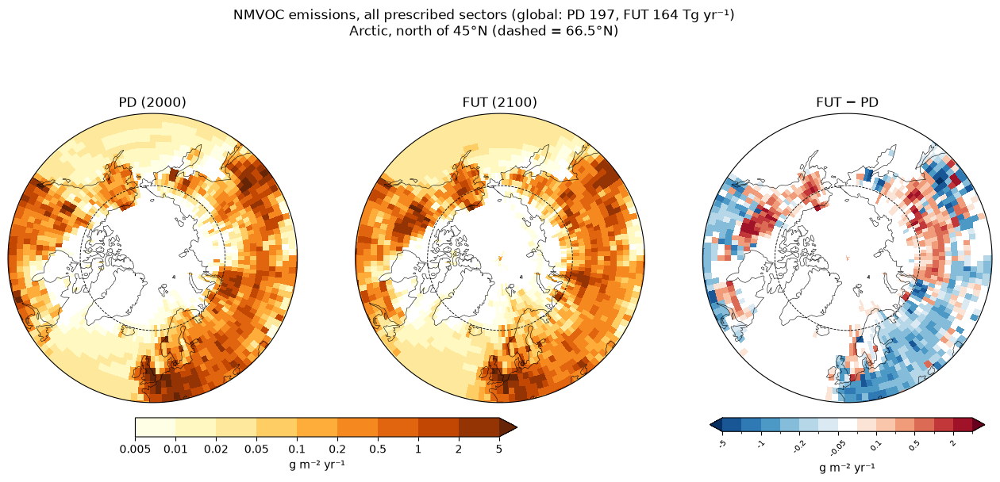

In [6]:
def group_map(period, g):
    mem = GROUPS[g]
    sel = MAPS.where((MAPS.period == period) & MAPS.species.isin(list(mem)), drop=True)
    w = xr.DataArray([mem[s] for s in sel.species.values], dims='entry')
    return (sel * w).sum('entry') * 1e3  # g m-2 yr-1

def nice_levels(vmax, decades=3):
    """1-2-5 levels from the first one >= vmax down by `decades` decades."""
    e = np.floor(np.log10(vmax))
    cand = np.array([m * 10.0**k for k in np.arange(e - decades - 1, e + 2) for m in (1, 2, 5)])
    hi = cand[cand >= vmax * 0.999][0]
    return cand[(cand <= hi) & (cand >= hi / 10**decades * 0.999)]

def cyclic(da):
    return xr.concat([da, da.isel(lon=0).assign_coords(lon=360.)], 'lon')

def map_axes(ncols, region, width=16):
    """Robinson (global) or north-polar stereographic north of LAT_MAP (arctic)."""
    if region == 'global':
        return plt.subplots(1, ncols, figsize=(width, 3.4), subplot_kw=dict(projection=ccrs.Robinson()))
    fig, axs = plt.subplots(1, ncols, figsize=(width, 6.2), subplot_kw=dict(projection=ccrs.NorthPolarStereo()))
    th = np.linspace(0, 2 * np.pi, 200)
    for ax in np.atleast_1d(axs):
        ax.set_extent([-180, 180, LAT_MAP, 90], ccrs.PlateCarree())
        ax.set_boundary(mpath.Path(np.c_[np.sin(th), np.cos(th)] * 0.5 + 0.5), transform=ax.transAxes)
    return fig, axs

def in_map(da, region):
    """Values inside the plotted domain (for the colour levels)."""
    return da if region == 'global' else da.where(da.lat >= LAT_MAP)

def white_zero(cmap, levels, extend='both'):
    """Same colours per bin as BoundaryNorm(levels, cmap.N, extend), except the bin that contains 0 is pure white."""
    cm = plt.get_cmap(cmap) if isinstance(cmap, str) else cmap
    levels = np.asarray(levels, float)
    off, n_ext = {'neither': (0, 0), 'min': (1, 1), 'max': (0, 1), 'both': (1, 2)}[extend]
    nreg = len(levels) - 1 + n_ext
    cols = cm(((cm.N - 1) / (nreg - 1) * np.arange(nreg)).astype(int))  # BoundaryNorm's bin -> colour index
    for i in range(len(levels) - 1):
        if levels[i] < 0 < levels[i + 1]:
            cols[i + off] = (1, 1, 1, 1)
    return mcolors.ListedColormap(cols), mcolors.BoundaryNorm(levels, nreg, extend=extend)

def draw(ax, da, cmap, norm):
    da = cyclic(da)
    da = da.where(abs(da) > 1e-6 * np.abs(norm.boundaries).max())  # (near-)zero -> not drawn = white
    im = ax.pcolormesh(da.lon, da.lat, da, cmap=cmap, norm=norm, transform=ccrs.PlateCarree(), shading='nearest')
    ax.coastlines(lw=0.4)
    if ax.projection.__class__.__name__ == 'NorthPolarStereo':  # Arctic Circle
        ax.plot(np.linspace(0, 360, 361), np.full(361, 66.5), ls='--', lw=0.6, color='k', transform=ccrs.PlateCarree())
    return im

def save_map(fig, fname, region):
    fig.savefig((FIG if region == 'arctic' else FIG_GLOBAL) / fname, dpi=200, bbox_inches='tight')
    plt.show()

def region_note(region):
    return f'Arctic, north of {LAT_MAP}°N (dashed = 66.5°N)' if region == 'arctic' else 'global'

def triptych(fields, title, unit, fname, decades=3, labels=None, region='arctic'):
    """fields = {'PD': da, 'FUT': da}; log-scale absolute, symmetric log-spaced difference.
    Colour levels from the plotted domain. Arctic calls are queued for the global Appendix."""
    if region == 'arctic':
        APPENDIX.append((triptych, (fields, title, unit, fname), dict(decades=decades, labels=labels)))
    pd_, fu = fields['PD'], fields['FUT']
    diff = fu - pd_
    vmax = float(np.nanpercentile(np.r_[in_map(pd_, region).values.ravel(), in_map(fu, region).values.ravel()], 99.5))
    lv = nice_levels(vmax, decades)
    cm_abs = plt.get_cmap('YlOrBr').copy()
    cm_abs.set_under('white')
    norm_abs = mcolors.BoundaryNorm(lv, cm_abs.N, extend='max')
    dmax = float(np.nanpercentile(abs(in_map(diff, region).values), 99.5))
    dl = nice_levels(dmax, decades - 1)
    dlev = np.r_[-dl[::-1], dl]  # the central bin (-dl[0], dl[0]) is white
    cm_d, norm_d = white_zero('RdBu_r', dlev)
    fig, axs = map_axes(3, region)
    labels = labels or {'PD': f'PD ({CYCLE["PD"]})', 'FUT': f'FUT ({CYCLE["FUT"]})'}
    for ax, (lab, da) in zip(axs[:2], [(labels['PD'], pd_), (labels['FUT'], fu)]):
        im = draw(ax, da, cm_abs, norm_abs)
        ax.set_title(lab)
    fig.colorbar(im, ax=axs[:2], orientation='horizontal', shrink=0.6, pad=0.04, ticks=lv, label=unit,
                 format=lambda x, _: f'{x:g}')
    im = draw(axs[2], diff, cm_d, norm_d)
    axs[2].set_title('FUT − PD')
    cb = fig.colorbar(im, ax=axs[2], orientation='horizontal', shrink=0.95, pad=0.04, ticks=dlev[::2] if len(dlev) > 12 else dlev,
                      label=unit, format=lambda x, _: f'{x:g}')
    cb.ax.tick_params(labelsize=7, rotation=45)
    fig.suptitle(f'{title}\n{region_note(region)}', y=1.06)
    save_map(fig, fname, region)

for g in GROUPS:
    short = g.split()[0]
    unit = 'g ' + g.split('(Tg')[1].strip(' )') + ' m⁻² yr⁻¹' if '(Tg ' in g else 'g m⁻² yr⁻¹'
    triptych({p: group_map(p, g) for p in CASES}, f'{short} emissions, all prescribed sectors '
             f'(global: PD {TOTAL.loc[g, "PD"]:.3g}, FUT {TOTAL.loc[g, "FUT"]:.3g} {g.split("(")[1].strip(")")} yr⁻¹)',
             unit, f'emission_map_{short}.png')

Biomass burning alone (part of every map above), because it is prescribed in both periods and it is the sector closest to the boreal region of the paper.

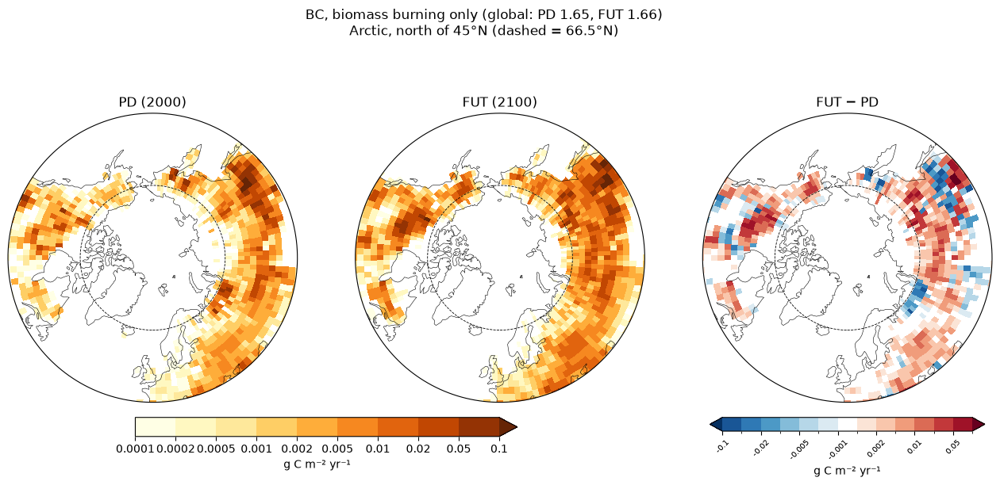

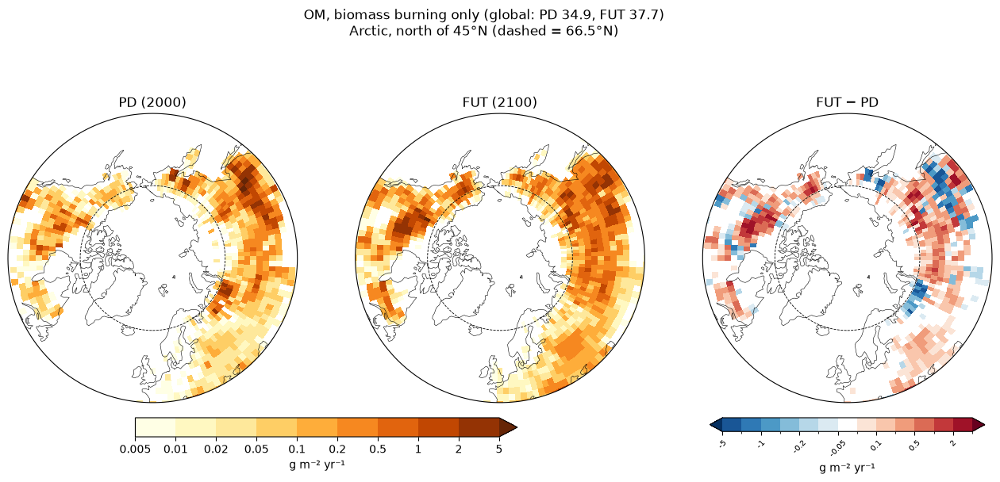

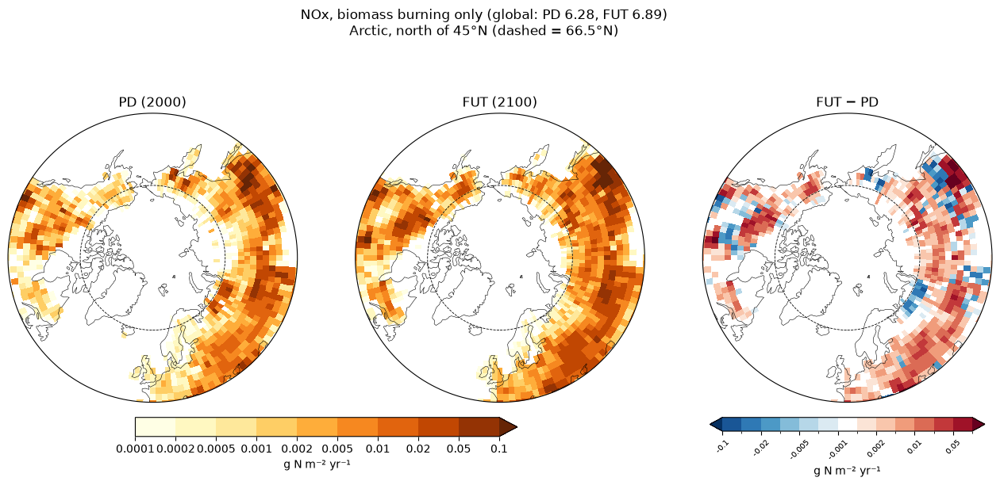

In [7]:
def sector_map(period, g, sec):
    mem = GROUPS[g]
    sel = MAPS.where((MAPS.period == period) & MAPS.species.isin(list(mem)) & (MAPS.sector == sec), drop=True)
    w = xr.DataArray([mem[s] for s in sel.species.values], dims='entry')
    return (sel * w).sum('entry') * 1e3

for g in ['BC (Tg C)', 'OM (Tg)', 'NOx (Tg N)']:
    short = g.split()[0]
    unit = 'g ' + g.split('(Tg')[1].strip(' )') + ' m⁻² yr⁻¹' if '(Tg ' in g else 'g m⁻² yr⁻¹'
    b = BYSEC.loc[(g, 'biomass burning')]
    triptych({p: sector_map(p, g, 'biomass burning') for p in CASES},
             f'{short}, biomass burning only (global: PD {b.PD:.3g}, FUT {b.FUT:.3g})', unit, f'emission_map_{short}_biomass_burning.png')

## 5. Ocean DMS concentration (input)

The DMS flux is computed online from this seawater concentration and the wind speed, so the flux itself is not prescribed (and `SFDMS` is not in the output). Annual mean, weighted by days per month.

PD dms-hamocc-dow-taylor_chlor_a-lanaclim_NHIST_f19_tn14_20190710_1995-2005_cycle_version20260209.nc
FUT dms-hamocc-dow-taylor_chlor_a-lanaclim_NSSP585frc2_f19_tn14_20191014_2090-2100_cycle_version20260209.nc
ocean-area mean DMS (nmol/L): {'PD': 2.04, 'FUT': 1.903} FUT/PD = 0.933


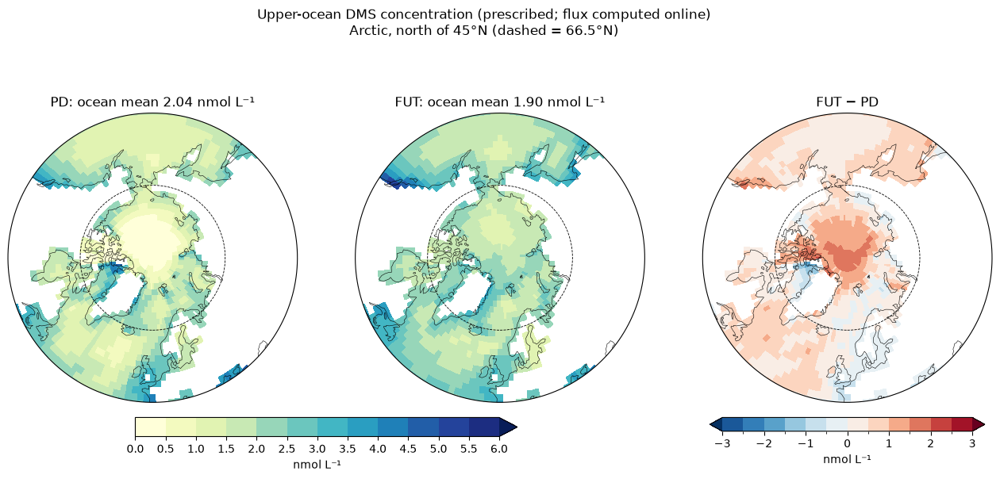

In [8]:
def nml(period, key):
    txt = (CASEDIR / CASES[period] / 'CaseDocs/atm_in').read_text()
    return re.search(rf"{key}\s*=\s*'?([^'\n]+?)'?\s*\n", txt).group(1).strip()

DMS = {}
for p in CASES:
    f = DMS_DIR / nml(p, 'ocean_filename')
    print(p, f.name)
    with xr.open_dataset(f, decode_times=False) as ds:
        assert ds.sizes['time'] == 12
        assert np.allclose(ds.lat, MAPS.lat) and np.allclose(ds.lon, MAPS.lon)
        ann = (ds.dms.fillna(0) * xr.DataArray(DPM, dims='time')).sum('time') / DPM.sum()
        DMS[p] = ann.where(ann > 0).assign_coords(lat=MAPS.lat, lon=MAPS.lon)  # land = 0 -> NaN
ocean = DMS['PD'].notnull() & DMS['FUT'].notnull()
mean = {p: float((DMS[p] * AREA).where(ocean).sum() / AREA.where(ocean).sum()) for p in CASES}
print('ocean-area mean DMS (nmol/L):', {p: round(v, 3) for p, v in mean.items()}, f'FUT/PD = {mean["FUT"] / mean["PD"]:.3f}')

def dms_maps(region='arctic'):
    if region == 'arctic':
        APPENDIX.append((dms_maps, (), {}))
    fig, axs = map_axes(3, region)
    lv = np.arange(0, 6.5, 0.5)
    norm = mcolors.BoundaryNorm(lv, plt.get_cmap('YlGnBu').N, extend='max')
    for ax, p in zip(axs[:2], CASES):
        im = draw(ax, DMS[p], 'YlGnBu', norm)
        ax.set_title(f'{p}: ocean mean {mean[p]:.2f} nmol L⁻¹')
    fig.colorbar(im, ax=axs[:2], orientation='horizontal', shrink=0.6, pad=0.04, ticks=lv, label='nmol L⁻¹')
    dl = np.arange(-3, 3.5, 0.5)
    im = draw(axs[2], DMS['FUT'] - DMS['PD'], *white_zero('RdBu_r', dl))
    axs[2].set_title('FUT − PD')
    fig.colorbar(im, ax=axs[2], orientation='horizontal', shrink=0.95, pad=0.04, ticks=dl[::2], label='nmol L⁻¹')
    fig.suptitle(f'Upper-ocean DMS concentration (prescribed; flux computed online)\n{region_note(region)}', y=1.06)
    save_map(fig, 'ocean_dms_concentration.png', region)

dms_maps()


## 6. What the model makes of it: CTRL_PD vs CTRL_FUT, 2001–2025

Processed monthly files, 2001–2025 (first 12 months already dropped), means weighted by days per month. Surface = lowest model level. These are model results, so they include the online sources (sea salt, dust, DMS, MEGAN) and the FUT climate (SST, CO₂), not only the prescribed emissions. Both runs are nudged to the same PD winds.

**Regions.** global, NH, SH, **46–82°N** and Arctic (>66.5°N). 46–82°N is the **forest-expansion band**: the only latitudes where the LCC land cover (`PCT_NAT_PFT`) differs from CTRL (46.4–82.4°N, from a diff of the two surfdata files). It is the same band as in the other diagnostics, so the numbers can be compared. It is **not** a 45–90°N box: the ocean and Greenland north of 82°N are left out because their land cover does not change; the Arctic row covers the pole. Maps: Arctic (north of 45°N); the map titles give the Arctic (>66.5°N) mean. Global maps in the Appendix.

In [9]:
MODEL_VARS = {  # name: (category, variable(s), surface?, factor, unit)
    'AOD 550 nm': ('AEROPT', ['DOD550'], False, 1, '1'),
    'absorption AOD 550 nm': ('AEROPT', ['ABS550'], False, 1, '1'),
    'sulfate burden': ('SULFATE', ['cb_SULFATE'], False, 1e6, 'mg m⁻²'),
    'droplet column': ('CLOUDPROP', ['CDNUMC'], False, 1e-10, '10¹⁰ m⁻²'),
    'surface SO₂': ('SULFATE', ['SO2'], True, 1e12, 'ppt'),
    'surface DMS': ('SULFATE', ['DMS'], True, 1e12, 'ppt'),
    'surface NOx': ('CHEM', ['NO', 'NO2'], True, 1e12, 'ppt'),
    'surface O₃': ('CHEM', ['O3'], True, 1e9, 'ppb'),
    'surface CO': ('CHEM', ['CO'], True, 1e9, 'ppb'),
    'O₃ column': ('CHEM', ['cb_O3'], False, 1e3, 'g m⁻²'),
}

def load_model(period):
    out, files = {}, {}
    for name, (cat, vs, sfc, fac, unit) in MODEL_VARS.items():
        f = PROC / f'{ALIAS[period]}_atm_{cat}_{PROC_YEARS}.nc'
        if f not in files:
            files[f] = xr.open_dataset(f)
        ds = files[f]
        assert ds.attrs['casename'] == CASES[period], (f, ds.attrs['casename'])
        assert ds.time.encoding.get('calendar') == 'noleap'
        da = sum(ds[v].isel(lev=-1) if sfc else ds[v] for v in vs)
        days = (ds.time_bnds[:, 1] - ds.time_bnds[:, 0]).dt.days
        out[name] = ((da * days).sum('time') / days.sum()).load() * fac
    assert all(float(ds.lev[-1]) > 900 for ds in files.values() if 'lev' in ds.dims)
    return out

MODEL = {p: load_model(p) for p in CASES}
for p in CASES:
    for k in MODEL[p]:
        assert np.allclose(MODEL[p][k].lat, MAPS.lat) and np.allclose(MODEL[p][k].lon, MAPS.lon)
        MODEL[p][k] = MODEL[p][k].assign_coords(lat=MAPS.lat, lon=MAPS.lon)

LAT = AREA.lat.broadcast_like(AREA)
REGIONS = {'global': AREA, 'NH': AREA * (LAT > 0), 'SH': AREA * (LAT < 0), '46–82°N': AREA * ((LAT >= 46) & (LAT <= 82)),
           'Arctic >66.5°N': AREA * (LAT > 66.5)}
rows = []
for name, (_, _, _, _, unit) in MODEL_VARS.items():
    for r, w in REGIONS.items():
        v = {p: float((MODEL[p][name] * w).sum() / w.sum()) for p in CASES}
        rows.append(dict(variable=name, unit=unit, region=r, PD=v['PD'], FUT=v['FUT'], **{'FUT − PD': v['FUT'] - v['PD'],
                         'change %': 100 * (v['FUT'] / v['PD'] - 1)}))
MODEL_TAB = pd.DataFrame(rows).set_index(['variable', 'unit', 'region'])
MODEL_TAB.to_csv(TAB / f'model_levels_ctrl_pd_fut_{PROC_YEARS}.csv')
with pd.option_context('display.float_format', '{:.3g}'.format, 'display.max_rows', 100):
    display(MODEL_TAB.xs('global', level='region'))
    display(MODEL_TAB.xs('46–82°N', level='region'))
    display(MODEL_TAB.xs('Arctic >66.5°N', level='region'))

,,PD,FUT,FUT − PD,change %
variable,unit,,,,
AOD 550 nm,1,0.203,0.216,0.013,6.4
absorption AOD 550 nm,1,0.00483,0.0044,-0.00043,-8.9
sulfate burden,mg m⁻²,6.23,3.78,-2.44,-39.3
droplet column,10¹⁰ m⁻²,1.16,1.05,-0.107,-9.22
surface SO₂,ppt,297,96.9,-200,-67.4
surface DMS,ppt,96.4,130,34.1,35.3
surface NOx,ppt,640,410,-231,-36
surface O₃,ppb,27.9,28.8,0.902,3.23
surface CO,ppb,79.6,104,23.9,30.1


,,PD,FUT,FUT − PD,change %
variable,unit,,,,
AOD 550 nm,1,0.135,0.114,-0.0209,-15.5
absorption AOD 550 nm,1,0.00341,0.00258,-0.000833,-24.4
sulfate burden,mg m⁻²,8.91,4.79,-4.13,-46.3
droplet column,10¹⁰ m⁻²,1.84,1.58,-0.256,-13.9
surface SO₂,ppt,526,82.2,-444,-84.4
surface DMS,ppt,49.8,138,87.9,177
surface NOx,ppt,1.07e+03,539,-527,-49.5
surface O₃,ppb,39.7,39.3,-0.39,-0.983
surface CO,ppb,98.1,106,8,8.16


,,PD,FUT,FUT − PD,change %
variable,unit,,,,
AOD 550 nm,1,0.0781,0.0649,-0.0133,-17
absorption AOD 550 nm,1,0.00218,0.00142,-0.000763,-35
sulfate burden,mg m⁻²,7.89,4.69,-3.2,-40.6
droplet column,10¹⁰ m⁻²,1.24,1.54,0.304,24.6
surface SO₂,ppt,166,41.8,-124,-74.7
surface DMS,ppt,37.3,191,154,413
surface NOx,ppt,161,169,7.56,4.69
surface O₃,ppb,40.8,39.9,-0.91,-2.23
surface CO,ppb,85.4,96.7,11.3,13.2


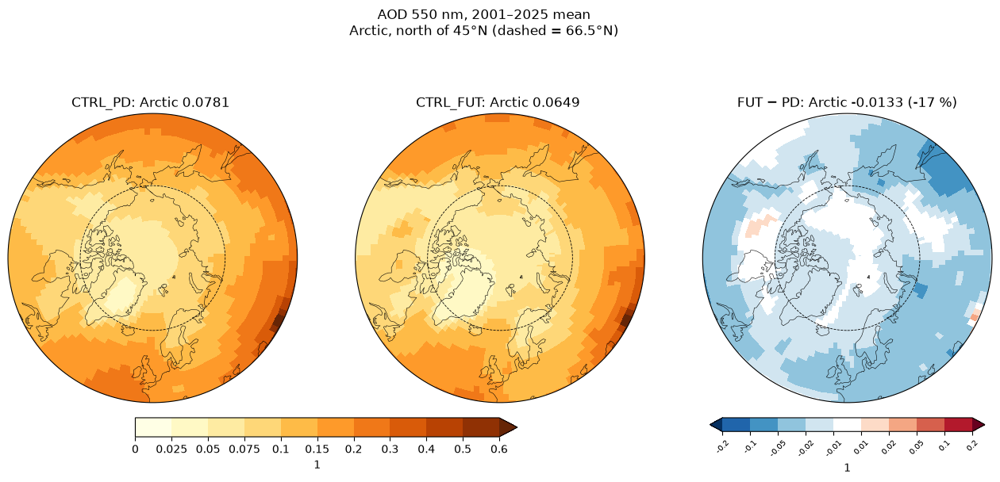

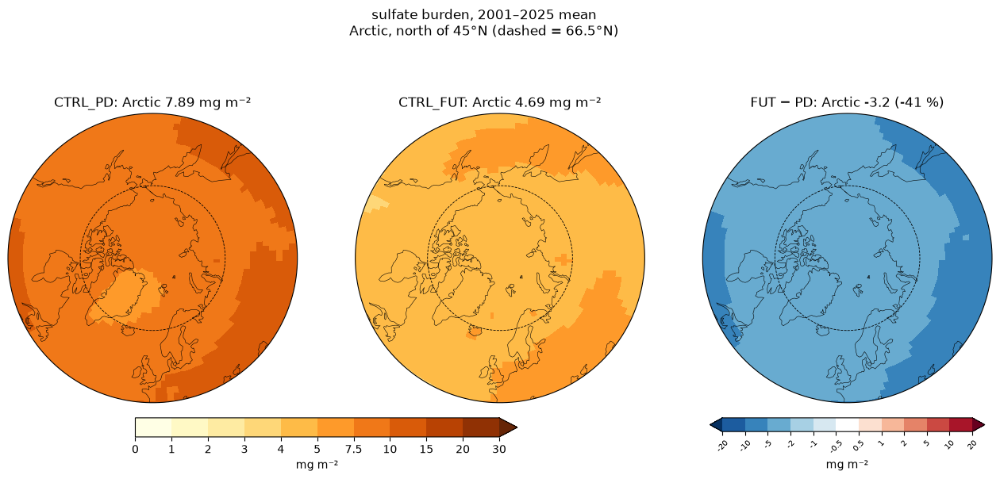

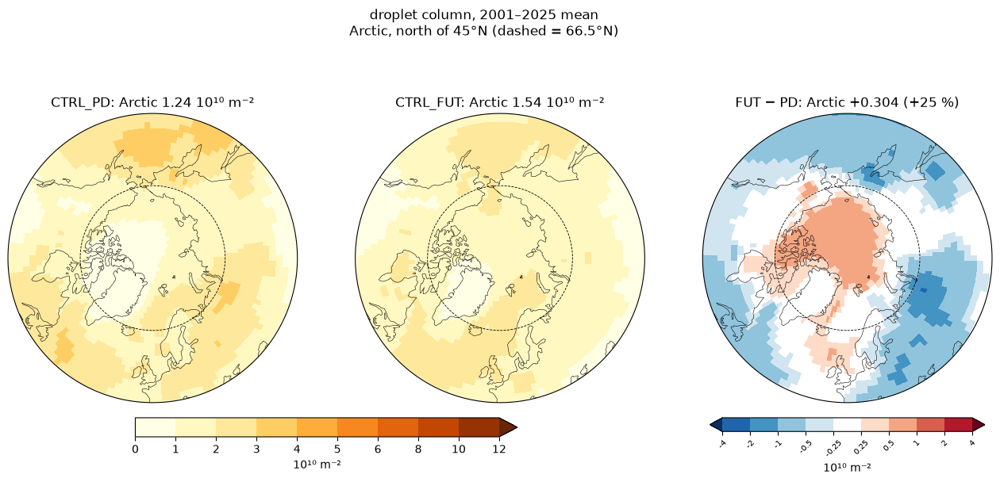

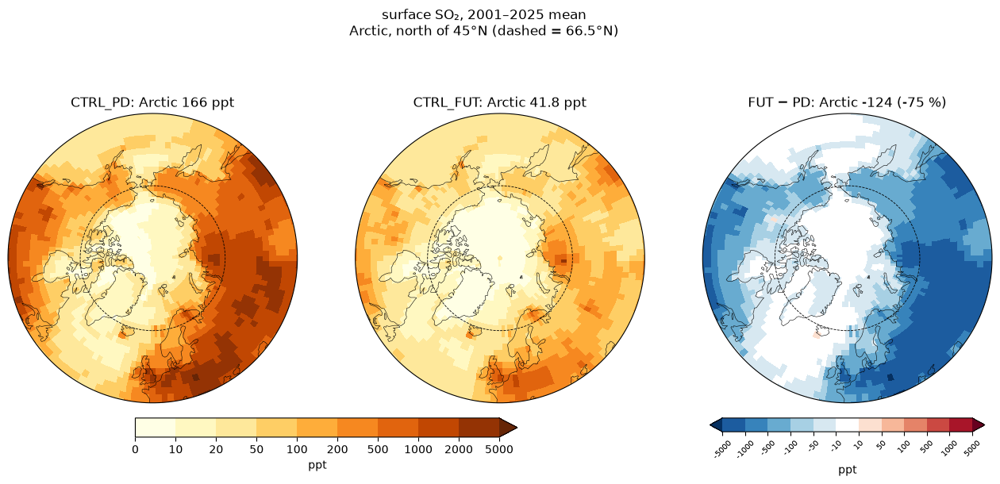

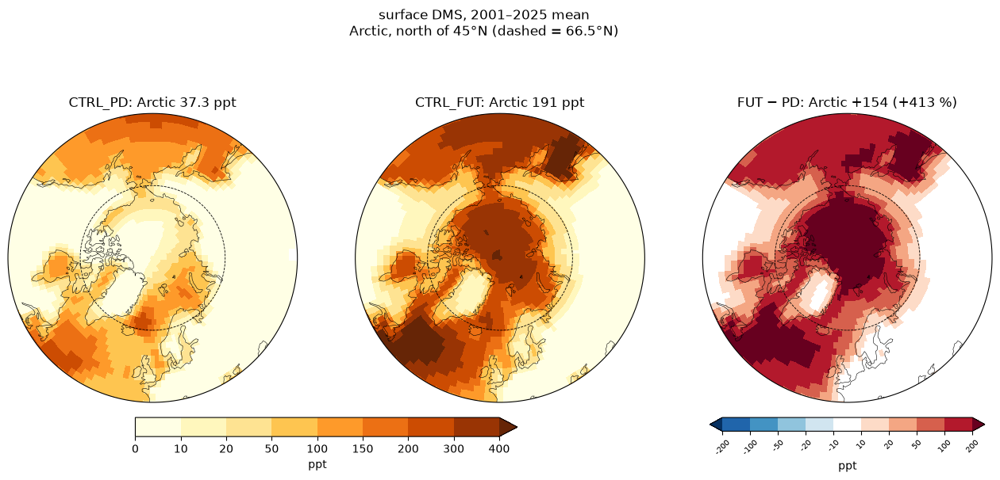

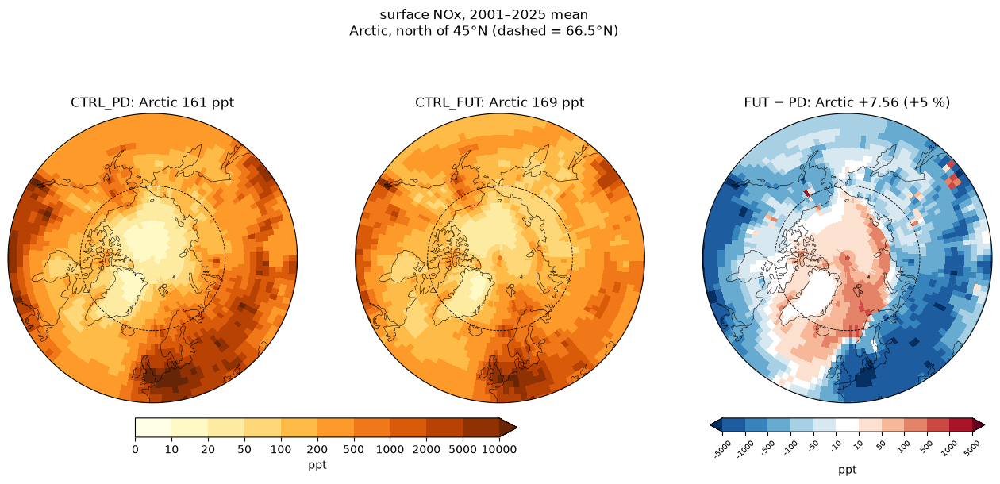

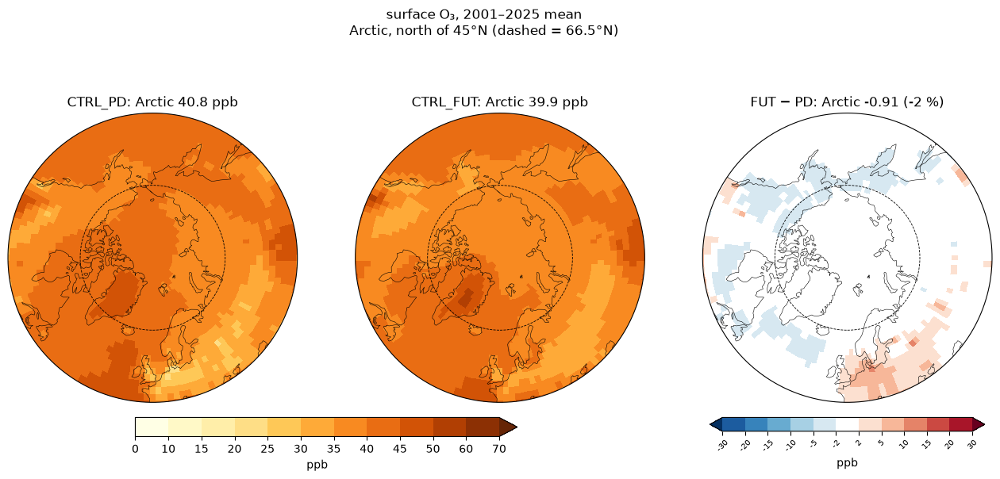

In [10]:
def triptych_lin(name, levels, dlevels, cmap='YlOrBr', region='arctic'):
    if region == 'arctic':
        APPENDIX.append((triptych_lin, (name, levels, dlevels), dict(cmap=cmap)))
    unit = MODEL_VARS[name][4]
    reg = 'Arctic >66.5°N' if region == 'arctic' else 'global'
    fig, axs = map_axes(3, region)
    norm = mcolors.BoundaryNorm(levels, plt.get_cmap(cmap).N, extend='max')
    g = MODEL_TAB.loc[(name, unit, reg)]
    rl = reg.split()[0]
    for ax, p in zip(axs[:2], CASES):
        im = draw(ax, MODEL[p][name], cmap, norm)
        ax.set_title(f'{ALIAS[p]}: {rl} {g[p]:.3g} {unit if unit != "1" else ""}')
    fig.colorbar(im, ax=axs[:2], orientation='horizontal', shrink=0.6, pad=0.04, ticks=levels, label=unit, format=lambda x, _: f'{x:g}')
    im = draw(axs[2], MODEL['FUT'][name] - MODEL['PD'][name], *white_zero('RdBu_r', dlevels))
    axs[2].set_title(f'FUT − PD: {rl} {g["FUT − PD"]:+.3g} ({g["change %"]:+.0f} %)')
    cb = fig.colorbar(im, ax=axs[2], orientation='horizontal', shrink=0.95, pad=0.04, ticks=dlevels, label=unit, format=lambda x, _: f'{x:g}')
    cb.ax.tick_params(labelsize=7, rotation=45)
    fig.suptitle(f'{name}, {YRS} mean\n{region_note(region)}', y=1.06)
    save_map(fig, f'model_map_{re.sub(r"[^A-Za-z0-9]+", "_", name.replace("₂", "2").replace("₃", "3")).strip("_")}.png', region)

sym = lambda *v: np.r_[-np.array(v[::-1]), np.array(v)]
triptych_lin('AOD 550 nm', [0, .025, .05, .075, .1, .15, .2, .3, .4, .5, .6], sym(.01, .02, .05, .1, .2))
triptych_lin('sulfate burden', [0, 1, 2, 3, 4, 5, 7.5, 10, 15, 20, 30], sym(.5, 1, 2, 5, 10, 20))
triptych_lin('droplet column', [0, 1, 2, 3, 4, 5, 6, 8, 10, 12], sym(.25, .5, 1, 2, 4))
triptych_lin('surface SO₂', [0, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000], sym(10, 50, 100, 500, 1000, 5000))
triptych_lin('surface DMS', [0, 10, 20, 50, 100, 150, 200, 300, 400], sym(10, 20, 50, 100, 200))
triptych_lin('surface NOx', [0, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000], sym(10, 50, 100, 500, 1000, 5000))
triptych_lin('surface O₃', [0, 10, 15, 20, 25, 30, 35, 40, 45, 50, 60, 70], sym(2, 5, 10, 15, 20, 30))

## 7. Time series of the prescribed files (only one year is read)

Global annual totals of every file, by sector. **Solid** = PD files (CMIP6 historical, annual 1850–2014); **dashed with dots** = FUT files (SSP5-8.5; the files hold 2014, 2015, then every 10 years, plus 2301, not shown). The runs read only the year marked: **navy dot = PD (2000)**, **red dot = FUT (2100)**. Gold = sum of sectors. Stratospheric volcanic SO₂ is one 1850–2014 mean (same in both periods), drawn flat. The "natural" files repeat one year.

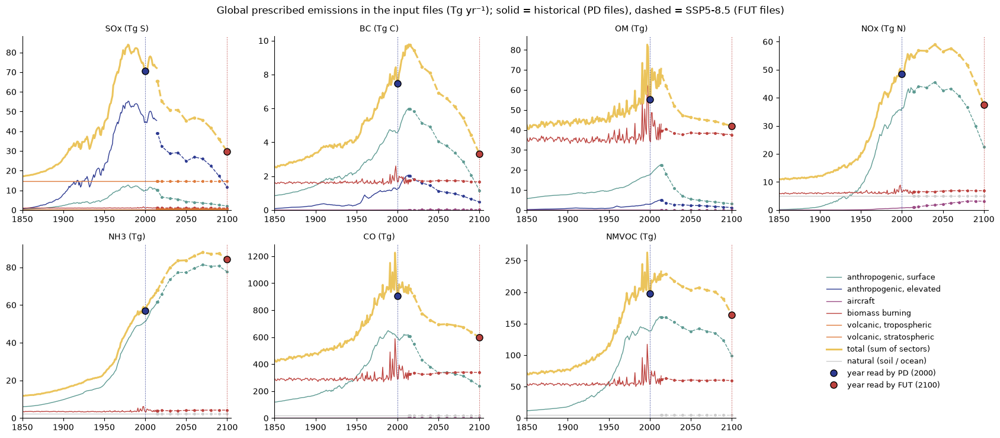

In [11]:
def group_series(period, g):
    mem = GROUPS[g]
    sub = TOT[(TOT.period == period) & TOT.species.isin(list(mem))]
    s = (sub.Tg * sub.species.map(mem)).groupby([sub.sector, sub.year]).sum().unstack('sector')
    span = (1850, 2014) if period == 'PD' else (2014, 2100)
    s = s.reindex(range(span[0], span[1] + 1))
    if 'volcanic, stratospheric' in s:  # one climatological year repeated
        s['volcanic, stratospheric'] = s['volcanic, stratospheric'].dropna().iloc[0]
    s = s.dropna(how='all')
    s['total'] = s.sum(axis=1, min_count=s.shape[1])  # only years with every sector
    return s

SERIES = {(p, g): group_series(p, g) for p in CASES for g in GROUPS}
pd.concat({f'{p}|{g}': s for (p, g), s in SERIES.items()}, names=['period|group']).to_csv(TAB / 'prescribed_file_timeseries_by_sector.csv')

fig, axs = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, g in zip(axs.flat, GROUPS):
    for p, ls, mk in [('PD', '-', None), ('FUT', '--', 'o')]:
        s = SERIES[p, g]
        for sec in [c for c in SECTORS if c in s]:
            d = s[sec].dropna()
            ax.plot(d.index, d.values, ls=ls, marker=mk, ms=2.5, lw=1, color=SCOL[sec],
                    label=sec if p == 'PD' or sec not in SERIES['PD', g] else None)
        d = s.total.dropna()
        ax.plot(d.index, d.values, ls=ls, marker=mk, ms=3, lw=2.2, color=GOLD, label='total (sum of sectors)' if p == 'PD' else None)
        y = CYCLE[p]
        ax.plot(y, s.total.get(y, np.nan), 'o', ms=8, mfc=PCOL[p], mec='k', zorder=5)
        ax.axvline(y, color=PCOL[p], lw=0.8, ls=':')
    ax.set_title(g, fontsize=10)
    ax.set_xlim(1850, 2105)
    ax.set_xticks(range(1850, 2101, 50))
    ax.set_ylim(bottom=0)
    ax.spines[['top', 'right']].set_visible(False)
h, l = [], []
for ax in axs.flat[:len(GROUPS)]:
    for hh, ll in zip(*ax.get_legend_handles_labels()):
        if ll not in l:
            h.append(hh); l.append(ll)
h += [plt.Line2D([], [], marker='o', ls='', mfc=PCOL[p], mec='k', ms=8) for p in CASES]
l += [f'year read by PD ({CYCLE["PD"]})', f'year read by FUT ({CYCLE["FUT"]})']
axs.flat[-1].axis('off')
axs.flat[-1].legend(h, l, loc='center', frameon=False, fontsize=9)
fig.suptitle('Global prescribed emissions in the input files (Tg yr⁻¹); solid = historical (PD files), dashed = SSP5-8.5 (FUT files)')
fig.tight_layout()
fig.savefig(FIG / 'prescribed_file_timeseries.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. Greenhouse-gas lower boundary condition (CH₄, N₂O, CO₂)

The surface mixing ratios of CH₄, N₂O, CO₂ and the halocarbons are prescribed (`flbc_file`, `CYCLICAL`, one year repeated: PD 2000, FUT 2100). CH₄ matters for chemistry: its oxidation makes **CO and O₃** and uses **OH**. Global means of the boundary file (cos-latitude weighted, mean of the 12 months), and the model surface CH₄ (lowest level, 2001–2025) as a check.

In [12]:
import gzip
ARCHIVES = [Path('/cluster/work/users/adelez/archive'), Path.home() / 'BRL-FRST-XPSN_archive']  # live archive first (has 2015–2025)
SEC_YR = 365 * 86400
MW_DMS, MW_S = 62.13, 32.06
# Salter et al. (2015) sea-salt number flux, 3 modes: coefficients of SST³, SST², SST, 1 (oslo_aero_seasalt.F90)
SS_COEF = np.array([[-5.2168e5, 3.31725e7, -6.95275e8, 1.0684e10],
                    [0.0,       7.374e5,  -2.4803e7,   7.7373e8],
                    [0.0,       1.4210e4,  1.4662e7,   1.7075e8]])

def read_nml(case, key, fname='atm_in'):
    txt = (CASEDIR / case / 'CaseDocs' / fname).read_text()
    return re.search(rf"\b{key}\s*=\s*(.*?)\n\s*(?:\w+\s*=|/)", txt, re.S).group(1).strip()

def xml_value(case, key):
    for f in sorted((CASEDIR / case).glob('env_*.xml')):
        m = re.search(rf'id="{key}" value="([^"]*)"', f.read_text())
        if m:
            return m.group(1)
    raise KeyError(key)

def yearly(da, years):
    """Monthly means -> calendar-year means weighted by days per month; dims (year, lat, lon)."""
    w = da.time.dt.days_in_month
    out = (da * w).groupby('time.year').sum('time') / w.groupby('time.year').sum('time')
    assert set(years) <= set(out.year.values.tolist()), (years, out.year.values)
    return out.sel(year=list(years))

def hist_files(case, comp, years):
    """Raw monthly h0 files of `years`, from the first archive that has all of them."""
    tag = 'clm2' if comp == 'lnd' else 'cam'
    for root in ARCHIVES:
        fs = [root / case / comp / 'hist' / f'{case}.{tag}.h0.{y}-{m:02d}.nc' for y in years for m in range(1, 13)]
        if all(f.is_file() for f in fs):
            return fs
    raise FileNotFoundError(f'{case} {comp} h0 {years[0]}–{years[-1]}')

# --- MEGAN: CAM species <- CLM compounds (megan_specifier in drv_flds_in) ---
def megan_groups(case):
    spec = re.findall(r"'([^']*)'", read_nml(case, 'megan_specifier', 'drv_flds_in'))
    return {k.strip(): [c.strip() for c in v.split('+')] for k, v in (s.split('=') for s in spec)}

def megan_yearly(alias, case, years):
    """kg m-2 s-1 per grid-cell area: sum of the CLM compounds of each CAM species x landfrac."""
    with xr.open_dataset(PROC / f'{alias}_lnd_BVOC_{PROC_YEARS}.nc') as ds:
        assert ds.attrs['casename'] == case, (alias, ds.attrs['casename'])
        lf = ds.landfrac.fillna(0)
        lf = lf.isel(time=0) if 'time' in lf.dims else lf
        out = {sp: yearly(sum(ds[f'MEG_{c}'].fillna(0) for c in comps) * lf, years)
               for sp, comps in megan_groups(case).items()}
    return xr.Dataset(out).assign_coords(lat=AREA.lat, lon=AREA.lon).load()

# --- dust: CLM DSTFLXT x landfrac x erodibility / dust_emis_fact x 1.15 (oslo_aero_dust_emis) ---
def _dust_month(args):
    path, fac = args
    with netCDF4.Dataset(path) as d:
        return np.ma.filled(d['DSTFLXT'][0], 0.) * np.ma.filled(d['landfrac'][:], 0.) * fac

def dust_yearly(alias, case, years):
    f = CACHE / f'dust_{alias}_{years[0]}-{years[-1]}.nc'
    if f.is_file() and not REBUILD_CACHE:
        da = xr.open_dataarray(f).load()
        assert np.allclose(da.lat, AREA.lat) and np.allclose(da.lon, AREA.lon)
        return da.assign_coords(lat=AREA.lat, lon=AREA.lon)  # same grid; avoid an outer join on float coords
    erod = xr.open_dataset(read_nml(case, 'soil_erod_file').strip("'")).mbl_bsn_fct_geo
    assert erod.shape == AREA.shape and np.allclose(erod.lat[1:-1], AREA.lat[1:-1])  # same grid (file poles at ±89.5)
    fac = np.where(erod.values < 0.1, 0., erod.values) / float(read_nml(case, 'dust_emis_fact').replace('D0', '')) * 1.15
    files = hist_files(case, 'lnd', years)
    with ProcessPoolExecutor(N_WORKERS) as ex:
        mon = np.stack(list(ex.map(_dust_month, [(p, fac) for p in files]))).reshape(len(years), 12, *AREA.shape)
    da = xr.DataArray((mon * DPM[None, :, None, None]).sum(1) / DPM.sum(), dims=('year', 'lat', 'lon'),
                      coords=dict(year=list(years), lat=AREA.lat, lon=AREA.lon), name='dust',
                      attrs=dict(units='kg m-2 s-1', case=case))
    da.to_netcdf(f)
    return da

# --- ocean: DMS flux and sea-salt number flux, offline from monthly means with the model formulas ---
def ocean_yearly(alias, case, years):
    """oslo_aero_ocean.F90 (DMS 'lana', HAMOCC transfer velocity) and oslo_aero_seasalt.F90 (Salter et al. 2015).
    Inputs: model U10, OCNFRAC, ICEFRAC (monthly), prescribed SST and seawater DMS (monthly climatologies)."""
    with xr.open_dataset(PROC / f'{alias}_atm_METEO_{PROC_YEARS}.nc') as ds:
        assert ds.attrs['casename'] == case, (alias, ds.attrs['casename'])
        m = ds[['U10', 'OCNFRAC', 'ICEFRAC']].load()
    with xr.open_dataset(xml_value(case, 'SSTICE_DATA_FILENAME'), decode_times=False) as s:
        sst = s.SST_cpl_prediddle.load()   # deg C
    with xr.open_dataset(DMS_DIR / read_nml(case, 'ocean_filename').strip("'"), decode_times=False) as s:
        dms = s.dms.fillna(0).load()       # nmol L-1
    for x in (sst, dms):
        assert x.sizes['time'] == 12 and np.allclose(x.lat, m.lat) and np.allclose(x.lon, m.lon)
    idx = m.time.dt.month.values - 1
    like = lambda x: xr.DataArray(x.values[idx], dims=m.U10.dims, coords=m.U10.coords)
    t, c, u = like(sst), like(dms), m.U10
    open_ = (m.OCNFRAC * (1 - m.ICEFRAC)).clip(0, 1)
    sc = 2855.7 + (-177.63 + (6.0438 + (-0.11645 + 0.00094743 * t) * t) * t) * t   # Schmidt number of DMS
    fdms = (MW_DMS * 6.97e-7 * open_ * u**2 * np.sqrt(660 / sc) * 1e-9 * c).fillna(0)  # kg DMS m-2 s-1
    wc = 2e-8 * u**3.74 * open_                                                        # whitecap fraction
    out = dict(DMS_flux=yearly(fdms, years), open_ocean=yearly(open_, years))
    for n, (a, b, cc, d) in enumerate(SS_COEF, 1):
        out[f'seasalt_n{n}'] = yearly((wc * (((a * t + b) * t + cc) * t + d)).fillna(0).clip(min=0), years)  # m-2 s-1
    return xr.Dataset(out).assign_coords(lat=AREA.lat, lon=AREA.lon).load()

# --- lightning NOx: CAM prints the global value every time step in atm.log ---
def lightning_yearly(case, years):
    f = CACHE / f'lightning_{case}.csv'
    if f.is_file() and not REBUILD_CACHE:
        s = pd.read_csv(f, index_col=0).iloc[:, 0]
    else:
        steps = int(xml_value(case, 'ATM_NCPL')) * 365
        logs = {}
        for root in ARCHIVES:
            for g in sorted((root / case / 'logs').glob('atm.log.*.gz')):
                logs.setdefault(g.name, g)
        out = {}
        for g in logs.values():
            y0, v = None, []
            with gzip.open(g, 'rt', errors='replace') as fh:
                for line in fh:
                    if 'lightning NOx (TgN/y)' in line:
                        v.append(float(line.rsplit('=', 1)[1].split()[1]))
                    elif y0 is None and 'Current date (yr mon day tod)' in line:
                        y0 = int(line.split(':')[1].split()[0])
            if len(v) % steps == 1:   # the first segment also prints step 0
                v = v[1:]
            assert len(v) % steps == 0, (g.name, len(v))
            for k in range(len(v) // steps):
                assert y0 + k not in out, (g.name, y0 + k)
                out[y0 + k] = float(np.mean(v[k * steps:(k + 1) * steps]))
        s = pd.Series(out, name='lightning NOx (Tg N/yr)').sort_index()
        s.to_csv(f)
    missing = set(years) - set(s.index)
    assert not missing, (case, sorted(missing))
    return s.loc[list(years)]

# --- greenhouse-gas lower boundary condition (flbc_file, cycle year) ---
def lbc_means(case, species=('CH4', 'N2O', 'CO2')):
    yr = int(read_nml(case, 'flbc_cycle_yr'))
    with xr.open_dataset(read_nml(case, 'flbc_file').strip("'"), decode_times=False) as ds:
        it = np.nonzero(ds.date.values // 10000 == yr)[0]
        assert len(it) == 12, (case, yr, len(it))
        w = np.cos(np.deg2rad(ds.lat))
        return yr, {sp: float((ds[f'{sp}_LBC'].isel(time=it).mean('time') * w).sum() / w.sum()) for sp in species}

In [13]:
rows = {}
for p in CASES:
    yr, v = lbc_means(CASES[p])
    with xr.open_dataset(PROC / f'{ALIAS[p]}_atm_CHEM_{PROC_YEARS}.nc') as ds:
        days = (ds.time_bnds[:, 1] - ds.time_bnds[:, 0]).dt.days
        ch4 = ((ds.CH4.isel(lev=-1) * days).sum('time') / days.sum()).load()
    assert np.allclose(ch4.lat, AREA.lat) and np.allclose(ch4.lon, AREA.lon)
    ch4 = ch4.assign_coords(lat=AREA.lat, lon=AREA.lon)  # same grid; avoid an inner join on float coords
    rows[p] = {'year read': yr, 'CH₄ (ppb)': v['CH4'] * 1e9, 'N₂O (ppb)': v['N2O'] * 1e9, 'CO₂ (ppm)': v['CO2'] * 1e6,
               f'model surface CH₄, {YRS} (ppb)': float((ch4 * AREA).sum() / AREA.sum()) * 1e9}
GHG = pd.DataFrame(rows)
GHG['FUT / PD'] = GHG.FUT / GHG.PD
GHG.loc['year read', 'FUT / PD'] = np.nan
GHG.to_csv(TAB / 'ghg_lower_boundary.csv')
with pd.option_context('display.float_format', '{:.4g}'.format):
    display(GHG)

,PD,FUT,FUT / PD
year read,2000,2100,NaN
CH₄ (ppb),1778,2415,1.358
N₂O (ppb),315.8,391.8,1.241
CO₂ (ppm),369.1,1135,3.075
"model surface CH₄, 2001–2025 (ppb)",1778,2415,1.358


## 9. Online sources: MEGAN BVOC, dust, sea salt, ocean DMS flux, lightning NOx

These are computed by the model every time step, so they respond to the FUT climate (and, in the LCC runs, to the land cover). CTRL_PD vs CTRL_FUT, 2001–2025. How each one is obtained:

| Source | What drives it in the model | How it is computed here | Evidence |
|---|---|---|---|
| **MEGAN BVOC** (19 CAM species) | CLM vegetation, leaf area, temperature, light, soil moisture, CO₂ | CLM `MEG_<compound>` (processed `lnd_BVOC`) × `landfrac`, summed into CAM species with `megan_specifier` (`drv_flds_in`) | (a) model output; check vs CAM `MEG_ISOP`, `MEG_MTERP` below |
| **Dust** | CLM: wind, soil moisture, snow, vegetation cover | raw CLM `DSTFLXT` × `landfrac` × erodibility (`soil_erod_file`, 0 below 0.1) / `dust_emis_fact` × 1.15, as `oslo_aero_dust_emis` | (a) formula; the result is what CAM receives (b): no CAM dust-emission output to check |
| **Sea salt** (3 modes, number flux) | 10-m wind (∝ U¹⁰^3.74), open ocean = ocean × (1 − ice), SST | Salter et al. (2015) formula of `oslo_aero_seasalt.F90` on **monthly means** of `U10`, `OCNFRAC`, `ICEFRAC` and the prescribed SST | (b): the model uses each time step; monthly means underestimate the absolute flux (U³·⁷⁴ is convex), the FUT/PD ratio is more robust |
| **Ocean DMS flux** | seawater DMS × transfer velocity (∝ U10² × Schmidt-number term of SST) × open ocean | `oslo_aero_dms_emis` (HAMOCC branch) on monthly means | (b), same caveat |
| **Lightning NOx** | convective cloud-top height (Price & Rind), `lght_no_prd_factor` | global value CAM prints every time step in `atm.log` (`Global flash freq …, lightning NOx (TgN/y)`), averaged per year | (a) model log; global only (no map in the output) |

No CAM output of sea-salt, dust or DMS emission exists in these runs (`D550_SS` and `SFDMS` not in `fincl`). Both periods use the **same nudged winds**, so a change in sea salt or DMS flux comes from sea ice, SST and (DMS) seawater concentration.

In [14]:
SRC, LIGHT = {}, {}
for p in CASES:
    meg = megan_yearly(ALIAS[p], CASES[p], YEARS)
    ocn = ocean_yearly(ALIAS[p], CASES[p], YEARS)
    SRC[p] = xr.merge([meg, ocn, dust_yearly(ALIAS[p], CASES[p], YEARS).rename('dust')])
    LIGHT[p] = lightning_yearly(CASES[p], YEARS)

# check: CLM compounds x landfrac reproduce what CAM receives from MEGAN (atm MEG_ISOP, MEG_MTERP)
for p in CASES:
    with xr.open_dataset(PROC / f'{ALIAS[p]}_atm_BVOC_{PROC_YEARS}.nc') as ds:
        for sp in ('ISOP', 'MTERP'):
            cam = yearly(ds[f'MEG_{sp}'], YEARS).assign_coords(lat=AREA.lat, lon=AREA.lon)
            r = float((SRC[p][sp] * AREA).sum() / (cam * AREA).sum())
            print(f'{p} {sp}: CLM-based / CAM MEG_{sp} = {r:.5f}')
            assert abs(r - 1) < 1e-3

MEG_OTHER = [v for v in megan_groups(CASES['PD']) if v not in ('ISOP', 'MTERP', 'BCARY', 'CH3OH')]
SRC_VARS = {  # name: (function of the yearly dataset -> kg or # m-2 s-1, factor to the total unit, unit)
    'MEGAN isoprene': (lambda d: d.ISOP, 1e-9, 'Tg yr⁻¹'),
    'MEGAN monoterpenes': (lambda d: d.MTERP, 1e-9, 'Tg yr⁻¹'),
    'MEGAN sesquiterpenes': (lambda d: d.BCARY, 1e-9, 'Tg yr⁻¹'),
    'MEGAN methanol': (lambda d: d.CH3OH, 1e-9, 'Tg yr⁻¹'),
    'MEGAN other (15 species)': (lambda d: sum(d[v] for v in MEG_OTHER), 1e-9, 'Tg yr⁻¹'),
    'dust': (lambda d: d.dust, 1e-9, 'Tg yr⁻¹'),
    'DMS flux (offline)': (lambda d: d.DMS_flux * MW_S / MW_DMS, 1e-9, 'Tg S yr⁻¹'),
    'sea salt, mode 1 (offline)': (lambda d: d.seasalt_n1, 1e-27, '10²⁷ yr⁻¹'),
    'sea salt, mode 2 (offline)': (lambda d: d.seasalt_n2, 1e-27, '10²⁷ yr⁻¹'),
    'sea salt, mode 3 (offline)': (lambda d: d.seasalt_n3, 1e-27, '10²⁷ yr⁻¹'),
    'open-ocean area': (lambda d: d.open_ocean / SEC_YR, 1e-12, '10⁶ km²'),
}
SRC_REG = {'global': AREA, '46–82°N': REGIONS['46–82°N'], 'Arctic >66.5°N': REGIONS['Arctic >66.5°N']}
rows = []
for name, (fn, fac, unit) in SRC_VARS.items():
    for r, w in SRC_REG.items():
        v = {p: float((fn(SRC[p]).mean('year') * w).sum()) * SEC_YR * fac for p in CASES}
        rows.append(dict(source=name, unit=unit, region=r, PD=v['PD'], FUT=v['FUT'],
                         **{'FUT − PD': v['FUT'] - v['PD'], 'change %': 100 * (v['FUT'] / v['PD'] - 1) if v['PD'] else np.nan}))
for r in ('global',):
    v = {p: LIGHT[p].mean() for p in CASES}
    rows.append(dict(source='lightning NOx', unit='Tg N yr⁻¹', region=r, PD=v['PD'], FUT=v['FUT'],
                     **{'FUT − PD': v['FUT'] - v['PD'], 'change %': 100 * (v['FUT'] / v['PD'] - 1)}))
SRC_TAB = pd.DataFrame(rows).set_index(['source', 'unit', 'region'])
SRC_TAB.to_csv(TAB / f'online_sources_ctrl_pd_fut_{PROC_YEARS}.csv')
pd.DataFrame(LIGHT).rename_axis('year').to_csv(TAB / 'lightning_nox_yearly.csv')
with pd.option_context('display.float_format', '{:.3g}'.format, 'display.max_rows', 100):
    display(SRC_TAB.xs('global', level='region'))
    display(SRC_TAB.xs('46–82°N', level='region'))

PD ISOP: CLM-based / CAM MEG_ISOP = 1.00000
PD MTERP: CLM-based / CAM MEG_MTERP = 0.99977
FUT ISOP: CLM-based / CAM MEG_ISOP = 1.00000
FUT MTERP: CLM-based / CAM MEG_MTERP = 0.99978


,,PD,FUT,FUT − PD,change %
source,unit,,,,
MEGAN isoprene,Tg yr⁻¹,509,885,377,74
MEGAN monoterpenes,Tg yr⁻¹,143,510,366,256
MEGAN sesquiterpenes,Tg yr⁻¹,13.3,56.9,43.6,328
MEGAN methanol,Tg yr⁻¹,104,298,194,186
MEGAN other (15 species),Tg yr⁻¹,222,721,499,225
dust,Tg yr⁻¹,3.8e+03,4.03e+03,226,5.95
DMS flux (offline),Tg S yr⁻¹,16.5,15.7,-0.772,-4.69
"sea salt, mode 1 (offline)",10²⁷ yr⁻¹,2.92,2.64,-0.276,-9.44
"sea salt, mode 2 (offline)",10²⁷ yr⁻¹,0.27,0.255,-0.0147,-5.45


,,PD,FUT,FUT − PD,change %
source,unit,,,,
MEGAN isoprene,Tg yr⁻¹,9.19,23.2,14,152
MEGAN monoterpenes,Tg yr⁻¹,7.78,34.7,26.9,346
MEGAN sesquiterpenes,Tg yr⁻¹,0.524,3.35,2.83,541
MEGAN methanol,Tg yr⁻¹,9.26,32.9,23.6,255
MEGAN other (15 species),Tg yr⁻¹,12,49.4,37.4,312
dust,Tg yr⁻¹,105,136,31.2,29.9
DMS flux (offline),Tg S yr⁻¹,0.697,0.999,0.301,43.2
"sea salt, mode 1 (offline)",10²⁷ yr⁻¹,0.246,0.226,-0.0201,-8.17
"sea salt, mode 2 (offline)",10²⁷ yr⁻¹,0.0212,0.0198,-0.00144,-6.79


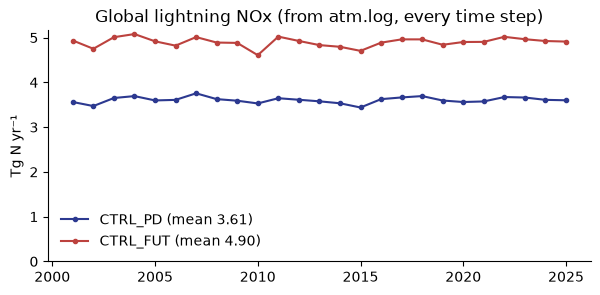

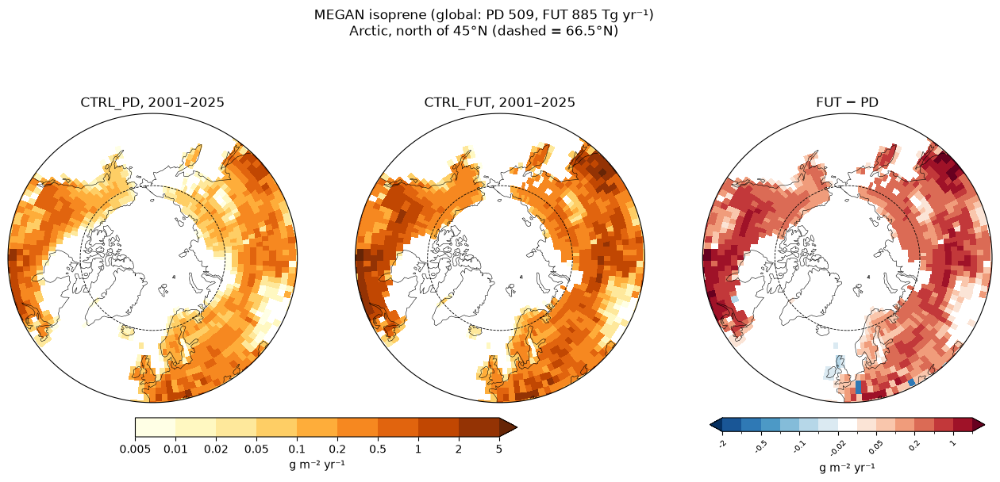

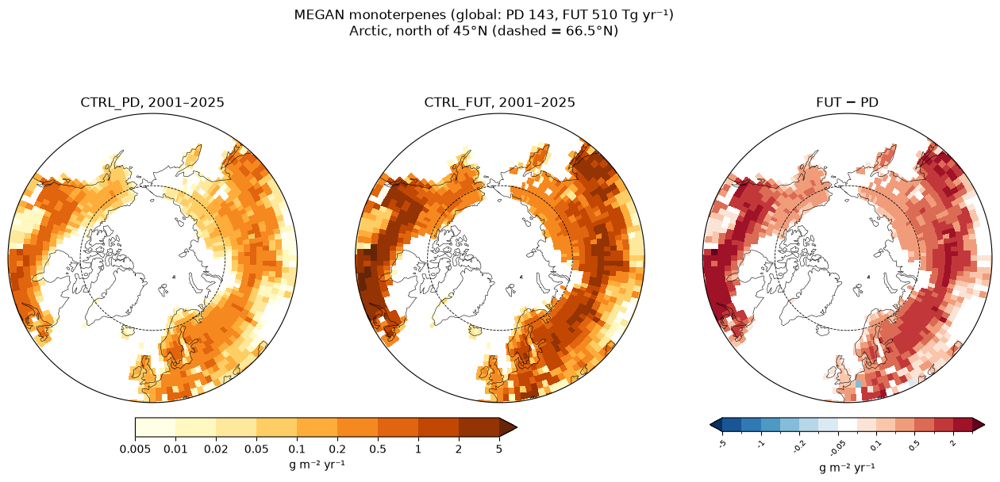

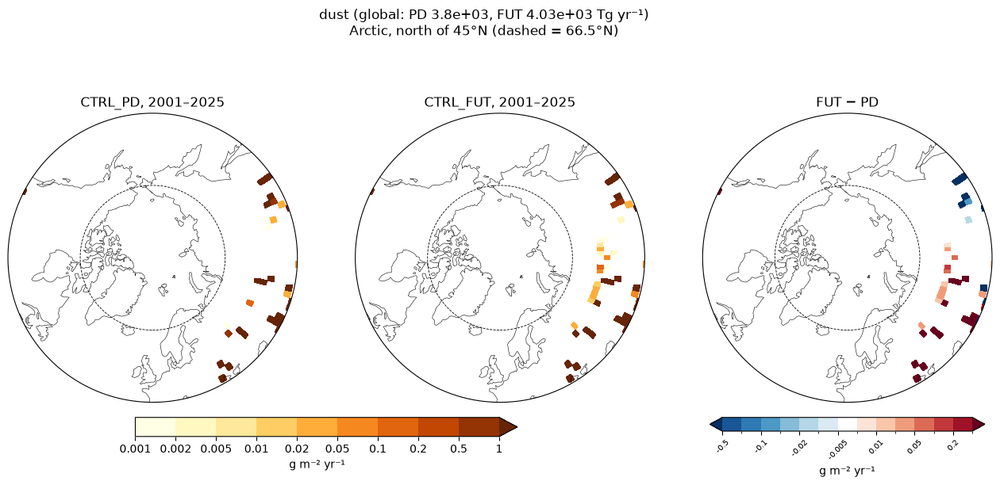

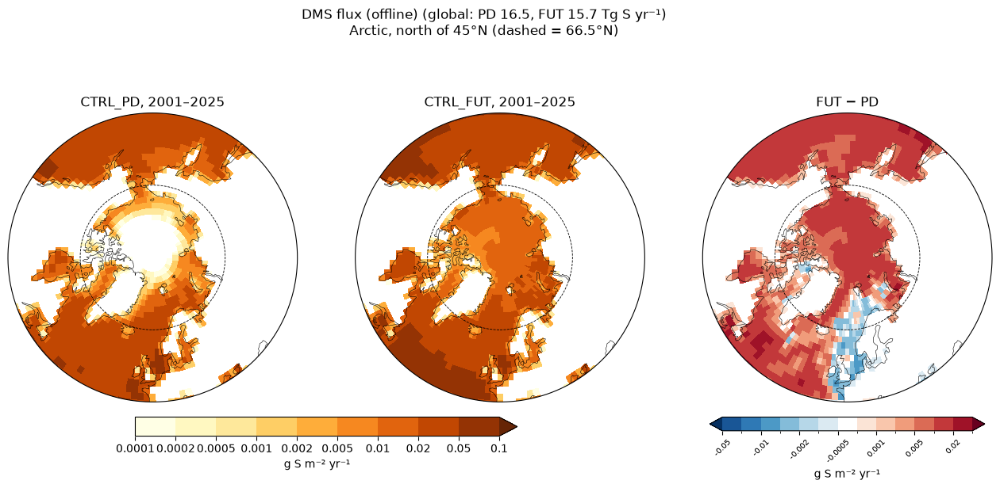

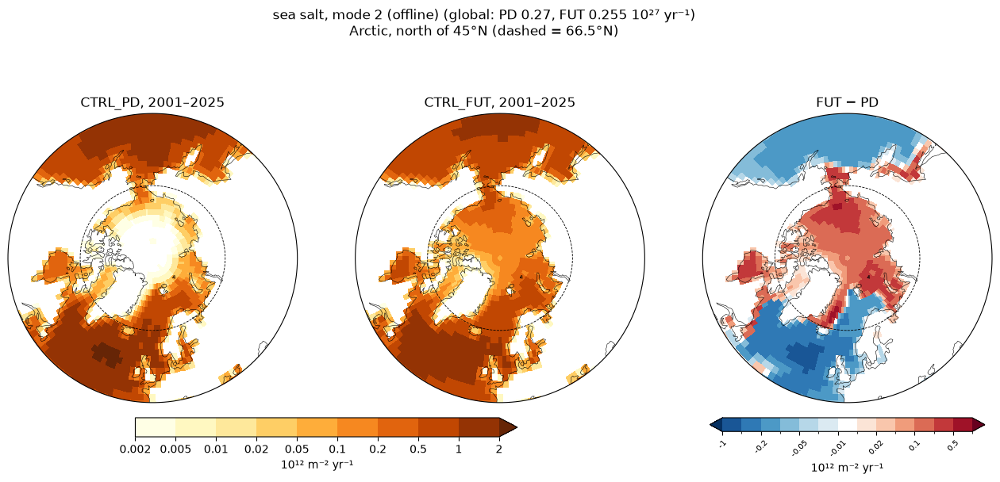

In [15]:
# lightning NOx per year
fig, ax = plt.subplots(figsize=(7, 3))
for p in CASES:
    ax.plot(LIGHT[p].index, LIGHT[p].values, 'o-', color=PCOL[p], ms=3, label=f'{ALIAS[p]} (mean {LIGHT[p].mean():.2f})')
ax.set_ylabel('Tg N yr⁻¹'); ax.set_title('Global lightning NOx (from atm.log, every time step)')
ax.set_ylim(bottom=0); ax.legend(frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.savefig(FIG / 'lightning_nox_yearly.png', dpi=200, bbox_inches='tight'); plt.show()

# maps of the online sources, 2001–2025 mean (Arctic; global in the Appendix)
lab = {p: f'{ALIAS[p]}, {YRS}' for p in CASES}
GLOB = SRC_TAB.xs('global', level='region')
for name, unit, fn, fname in [
        ('MEGAN isoprene', 'g m⁻² yr⁻¹', lambda d: d.ISOP * SEC_YR * 1e3, 'online_map_megan_isoprene.png'),
        ('MEGAN monoterpenes', 'g m⁻² yr⁻¹', lambda d: d.MTERP * SEC_YR * 1e3, 'online_map_megan_monoterpenes.png'),
        ('dust', 'g m⁻² yr⁻¹', lambda d: d.dust * SEC_YR * 1e3, 'online_map_dust.png'),
        ('DMS flux (offline)', 'g S m⁻² yr⁻¹', lambda d: d.DMS_flux * MW_S / MW_DMS * SEC_YR * 1e3, 'online_map_dms_flux.png'),
        ('sea salt, mode 2 (offline)', '10¹² m⁻² yr⁻¹', lambda d: d.seasalt_n2 * SEC_YR * 1e-12, 'online_map_seasalt_mode2.png')]:
    g = GLOB.loc[name]
    triptych({p: fn(SRC[p]).mean('year') for p in CASES},
             f'{name} (global: PD {g.PD.iloc[0]:.3g}, FUT {g.FUT.iloc[0]:.3g} {g.index[0]})', unit, fname, labels=lab)

### 9.1 Global totals and time series of the online sources

Same two figures as for the prescribed emissions (§3 and §7), for the online sources. **Bars** = global total, mean of the 25 years 2001–2025 (error bar = ±1 standard deviation of the yearly totals), stacked by component. **Time series** = global total of each year; **solid = CTRL_PD**, **dashed with dots = CTRL_FUT**; gold = sum of the components. MEGAN components as in the table above; sea salt = number flux of the three modes; DMS flux and sea salt offline from monthly means (see the table of §9).

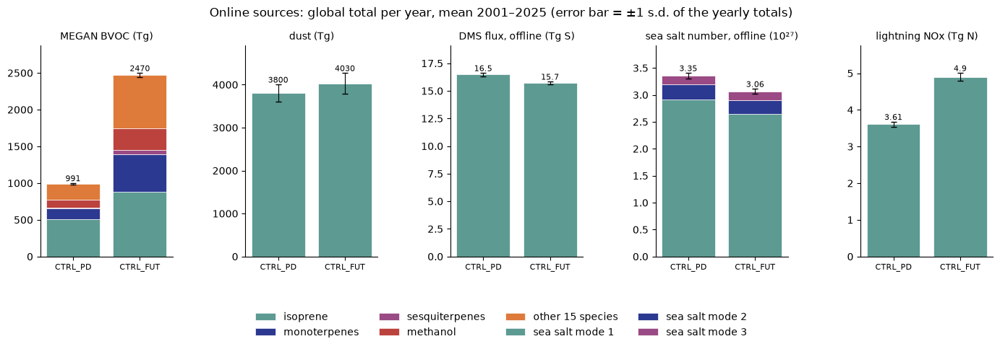

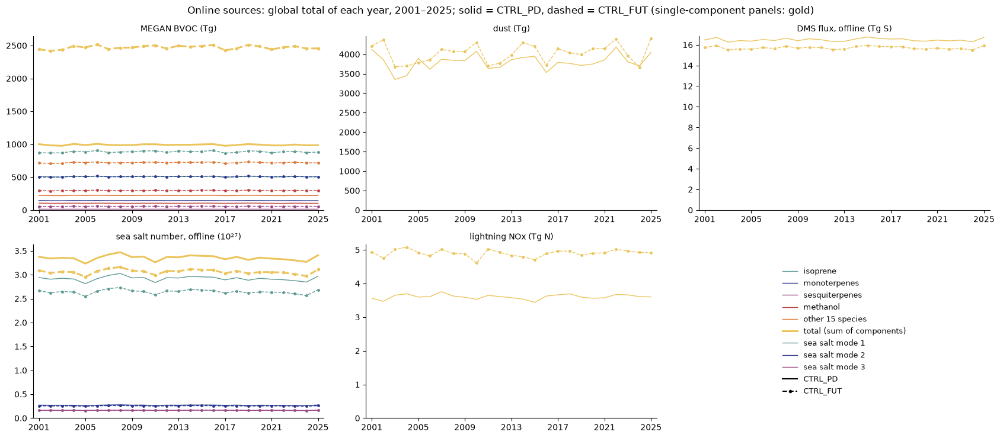

In [16]:
ONLINE = {  # panel -> {component: (function of SRC[p] -> kg or # m-2 s-1, factor to the panel unit)}
    'MEGAN BVOC (Tg)': {'isoprene': (lambda d: d.ISOP, 1e-9), 'monoterpenes': (lambda d: d.MTERP, 1e-9),
                        'sesquiterpenes': (lambda d: d.BCARY, 1e-9), 'methanol': (lambda d: d.CH3OH, 1e-9),
                        'other 15 species': (lambda d: sum(d[v] for v in MEG_OTHER), 1e-9)},
    'dust (Tg)': {'dust': (lambda d: d.dust, 1e-9)},
    'DMS flux, offline (Tg S)': {'DMS flux': (lambda d: d.DMS_flux * MW_S / MW_DMS, 1e-9)},
    'sea salt number, offline (10²⁷)': {f'sea salt mode {n}': (lambda d, n=n: d[f'seasalt_n{n}'], 1e-27) for n in (1, 2, 3)},
}
# yearly global totals: {(period, panel): DataFrame(year x component)}
ONL = {}
for p in CASES:
    for panel, comps in ONLINE.items():
        ONL[p, panel] = pd.DataFrame({c: (fn(SRC[p]) * AREA).sum(('lat', 'lon')).to_series() * SEC_YR * fac
                                      for c, (fn, fac) in comps.items()})
    ONL[p, 'lightning NOx (Tg N)'] = pd.DataFrame({'lightning NOx': LIGHT[p]})
PANELS = list(ONLINE) + ['lightning NOx (Tg N)']
COMPCOL = dict(zip(['isoprene', 'monoterpenes', 'sesquiterpenes', 'methanol', 'other 15 species'], [TEAL, NAVY, PLUM, RED, ORANGE]))
COMPCOL.update({'sea salt mode 1': TEAL, 'sea salt mode 2': NAVY, 'sea salt mode 3': PLUM,
                'dust': TEAL, 'DMS flux': TEAL, 'lightning NOx': TEAL})
for p in CASES:
    assert all(list(ONL[p, k].index) == YEARS for k in PANELS)
pd.concat({f'{ALIAS[p]}|{k}': ONL[p, k] for p in CASES for k in PANELS}, names=['run|panel', 'year']).to_csv(
    TAB / f'online_sources_global_yearly_{PROC_YEARS}.csv')
# check: the 25-year mean of the yearly totals = the global row of the table above
assert np.isclose(ONL['PD', 'MEGAN BVOC (Tg)'].isoprene.mean(), SRC_TAB.loc[('MEGAN isoprene', 'Tg yr⁻¹', 'global'), 'PD'], rtol=1e-6)
assert np.isclose(ONL['FUT', 'dust (Tg)'].dust.mean(), SRC_TAB.loc[('dust', 'Tg yr⁻¹', 'global'), 'FUT'], rtol=1e-6)

# --- bars: 2001-2025 mean, stacked by component ---
fig, axs = plt.subplots(1, len(PANELS), figsize=(17, 3.8), gridspec_kw=dict(wspace=0.55))
for ax, panel in zip(axs, PANELS):
    bottom = np.zeros(2)
    for c in ONL['PD', panel].columns:
        v = np.array([ONL[p, panel][c].mean() for p in CASES])
        ax.bar([0, 1], v, bottom=bottom, color=COMPCOL[c], edgecolor='white', lw=0.5, label=c)
        bottom += v
    sd = [ONL[p, panel].sum(axis=1).std(ddof=1) for p in CASES]
    ax.errorbar([0, 1], bottom, yerr=sd, fmt='none', ecolor='k', elinewidth=0.8, capsize=3)
    for x, (v, e) in enumerate(zip(bottom, sd)):
        ax.text(x, v + e, f'{float(f"{v:.3g}"):g}', ha='center', va='bottom', fontsize=8)
    ax.set_xticks([0, 1], [f'{ALIAS[p]}' for p in CASES], fontsize=8)
    ax.set_title(panel, fontsize=10)
    ax.set_ylim(0, (bottom + sd).max() * 1.15)
    ax.spines[['top', 'right']].set_visible(False)
h, l = [], []
for ax in axs:
    for hh, ll in zip(*ax.get_legend_handles_labels()):
        if ll not in l and ll not in ('dust', 'DMS flux', 'lightning NOx'):
            h.append(hh); l.append(ll)
fig.legend(h, l, loc='upper center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.06))
fig.suptitle(f'Online sources: global total per year, mean {YRS} (error bar = ±1 s.d. of the yearly totals)', y=1.02)
fig.savefig(FIG / 'online_totals_mean.png', dpi=200, bbox_inches='tight')
plt.show()

# --- time series of the yearly global totals ---
fig, axs = plt.subplots(2, 3, figsize=(17, 7.5))
for ax, panel in zip(axs.flat, PANELS):
    for p, ls, mk in [('PD', '-', None), ('FUT', '--', 'o')]:
        s = ONL[p, panel]
        multi = s.shape[1] > 1
        for c in s.columns:
            ax.plot(s.index, s[c].values, ls=ls, marker=mk, ms=2.5, lw=1, color=COMPCOL[c] if multi else GOLD,
                    label=(c if multi else 'total') if p == 'PD' else None)
        if multi:
            ax.plot(s.index, s.sum(axis=1).values, ls=ls, marker=mk, ms=3, lw=2.2, color=GOLD,
                    label='total (sum of components)' if p == 'PD' else None)
    ax.set_title(panel, fontsize=10)
    ax.set_xlim(YEARS[0] - 0.5, YEARS[-1] + 0.5)
    ax.set_xticks(range(2001, 2026, 4))
    ax.set_ylim(bottom=0)
    ax.spines[['top', 'right']].set_visible(False)
h, l = [], []
for ax in axs.flat[:len(PANELS)]:
    for hh, ll in zip(*ax.get_legend_handles_labels()):
        if ll not in l and ll != 'total':
            h.append(hh); l.append(ll)
h += [plt.Line2D([], [], color='k', ls='-'), plt.Line2D([], [], color='k', ls='--', marker='o', ms=3)]
l += [ALIAS['PD'], ALIAS['FUT']]
axs.flat[-1].axis('off')
axs.flat[-1].legend(h, l, loc='center', frameon=False, fontsize=9)
fig.suptitle(f'Online sources: global total of each year, {YRS}; solid = CTRL_PD, dashed = CTRL_FUT (single-component panels: gold)')
fig.tight_layout()
fig.savefig(FIG / 'online_timeseries.png', dpi=200, bbox_inches='tight')
plt.show()


## 10. Summary

Tags: **(a)** read from the tables above · **(b)** inference.

**Prescribed emissions, year read (PD 2000 → FUT 2100, global)** (a)

| | PD | FUT | FUT/PD | what changes |
|---|---|---|---|---|
| SOx (Tg S) | 70.6 | 29.7 | 0.42 | anthropogenic −80 % (54.5 → 13.6); tropospheric volcanic 14.6 and stratospheric 0.30 unchanged → **half of FUT SOx is volcanic** |
| BC (Tg C) | 7.47 | 3.32 | 0.44 | anthropogenic −72 %; biomass burning unchanged (1.65) |
| OM (Tg) | 55.4 | 42.1 | 0.76 | anthropogenic −79 %; biomass burning +8 % (34.9 → 37.7), 90 % of FUT OM |
| NOx (Tg N) | 48.4 | 37.4 | 0.77 | anthropogenic surface −38 %; aircraft ×3.9 (0.8 → 3.1); soil NOx identical |
| NH3 (Tg) | 57.0 | 84.2 | 1.48 | the only species that rises (agriculture) |
| CO (Tg) | 908 | 598 | 0.66 | anthropogenic −60 %, biomass burning +17 % |
| NMVOC (Tg) | 197 | 164 | 0.83 | anthropogenic −28 %, biomass burning +11 % |

- **Biomass burning is prescribed in both periods and changes by at most ±20 %**, so FUT is not a more fire-prone world in this setup. (a)
- PD reads one single year (2000), not a climatology. Biomass burning in the historical files varies a lot from year to year in 1997–2014 (GFED era, §7), so the PD fire emissions belong to that one year. (a)
- The ocean DMS concentration is 7 % lower in FUT (ocean mean 2.04 → 1.90 nmol L⁻¹). (a)

**What the model makes of it (CTRL_PD → CTRL_FUT, 2001–2025)** (a)

| | global | 46–82°N (forest-expansion band) | Arctic >66.5°N |
|---|---|---|---|
| sulfate burden | 6.23 → 3.78 mg m⁻² (−39 %) | −46 % | −41 % (7.89 → 4.69) |
| surface SO₂ | −67 % | −84 % | −75 % |
| surface NOx | −36 % | −50 % | +5 % |
| surface O₃ | +3 % (27.9 → 28.8 ppb) | −1 % | −2 % |
| surface CO | +30 % | +8 % | +13 % |
| surface DMS | +35 % | **+177 %** | **+413 %** |
| droplet column | −9 % | −14 % | **+25 %** |
| AOD 550 nm | **+6 %** (0.203 → 0.216) | −16 % | −17 % |
| absorption AOD | −9 % | −24 % | −35 % |

The 2001–2025 values differ from the earlier 2001–2014 ones by at most ~2 % (e.g. FUT surface DMS at 46–82°N 136 → 138 ppt); percent changes move by ≤ 1 point (old tables in `background_aerosol_pd_fut_outputs/2001-2014/`).

Inferences (b):
- Global AOD goes **up** although sulfate falls by 39 %. The increase sits over the Sahara/Arabia and the tropical oceans, which points to more dust and sea salt (and water uptake) in the warmer FUT climate. This is not verified: the output has no AOD per component (the `A550_*` fields are absorption).
- Surface DMS rises although seawater DMS falls. Likely causes: less sea ice (more open ocean in the Arctic, hence +176 % at 46–82°N) and slower oxidation with less NOx. Not checked.
- CO rises although CO emissions fall: probably the much higher CH₄ of SSP5-8.5 in 2100 (CH₄ oxidation makes CO). Not checked here.
- Ozone barely changes: lower NOx and higher CH₄/CO roughly cancel.

**Beyond the emission files (§8–9)** (a)

| | PD | FUT | change |
|---|---|---|---|
| surface CH₄ (boundary condition) | 1778 ppb | 2415 ppb | +36 % |
| surface N₂O / CO₂ | 316 ppb / 369 ppm | 392 ppb / 1135 ppm | +24 % / ×3.1 |
| MEGAN isoprene | 509 Tg yr⁻¹ | 885 | +74 % |
| MEGAN monoterpenes | 143 Tg yr⁻¹ | 510 | **×3.6** |
| MEGAN sesquiterpenes / methanol | 13 / 104 | 57 / 297 | ×4.3 / ×2.9 |
| dust | 3.8 Pg yr⁻¹ | 4.0 | +6 % (46–82°N +30 %) |
| DMS flux (offline) | 16.5 Tg S yr⁻¹ | 15.7 | −5 % globally, **+43 % at 46–82°N** |
| sea salt, number (offline) | | | −9 % (mode 1), −5 %, 0 % |
| open-ocean area 46–82°N | 22.0 × 10⁶ km² | 26.6 | +21 % (less sea ice) |
| lightning NOx | 3.6 Tg N yr⁻¹ | 4.9 | +36 % |

- The biggest change in the natural background is **MEGAN**: in FUT the land emits 3.6× more monoterpenes, the main SOA precursor. So the FUT background has **much less anthropogenic sulfate but much more biogenic SOA precursor**. (a)
- **CH₄ +36 %** explains at least part of the CO rise (+30 %) and the near-constant O₃. (b)
- **DMS:** at 46–82°N the flux rises by 43 % (21 % more open ocean, plus warmer water), yet surface DMS rises by 177 % (+413 % north of 66.5°N). The rest probably comes from slower oxidation (OH, NO₃). Not checked. (b)
- **NH₃ +48 %** has no aerosol of its own in OsloAero but raises cloud-water pH, which speeds up in-cloud SO₂ + O₃ → sulfate (`mo_setsox.F90`). This can partly offset the SO₂ cut; its size is not diagnosed. (a: mechanism; b: relevance)
- The dust total is reconstructed from CLM `DSTFLXT` with the CAM scaling; the absolute value (3.8–4.0 Pg yr⁻¹) is not checked against a model diagnostic. The FUT/PD ratio is what counts here. (b)

**Why it matters for the paper** (b)
1. **Fewer competing particles.** With 39–46 % less sulfate (−84 % surface SO₂ at 46–82°N), FUT has fewer pre-existing particles and fewer CCN. New SOA (from more BVOC) then forms or grows particles in a cleaner air mass, where each extra CCN changes cloud droplets more (cloud susceptibility is higher at low droplet number). The **same BVOC change can have a larger aerosol–cloud effect in FUT than in PD.**
2. **A larger natural share.** At high latitudes more of the remaining sulfate comes from DMS (more open ocean) and volcanoes. DMS also makes some SOA precursors in this mechanism. So the forest's BVOC adds to a background that is **more marine and more biogenic**, not to a polluted one.
3. **Higher BVOC baseline.** FUT CTRL already emits 3.6× more monoterpenes than PD. An extra forest source is a smaller *relative* addition in FUT, and SOA formation may saturate (less oxidant per BVOC; more condensation surface from SOA itself).
4. **Implication.** Points 1 and 3 push in opposite directions, so the size of the FUT forest-expansion aerosol effect cannot be guessed from PD. It has to come from the runs (the LCC_FUT − CTRL_FUT companion notebook: very small).

**For the paper:** FUT is a **clean-air background** for anthropogenic aerosol (sulfate, BC, anthropogenic OM, NOx), with unchanged fires and volcanoes. BVOC-driven SOA formation and aerosol–cloud effects of the forest expansion therefore act on a lower sulfate/CCN background in FUT. (b)


**Arctic (b, not checked):** in the Arctic the droplet column goes **up** by 25 % although sulfate falls by 41 %, unlike the global and 46–82°N means. It coincides with the large DMS rise (more open ocean) and possibly more cloud/sea-salt over newly ice-free water; not separated here.

## Appendix: global maps

The same maps as in §4–6 and §9, over the whole globe (Robinson projection). Colour levels of §4 and §9 are recomputed from the global fields. Files in `figures/appendix-global/`.

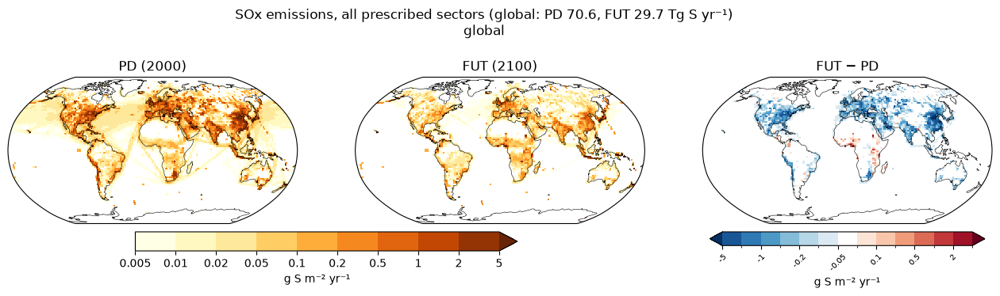

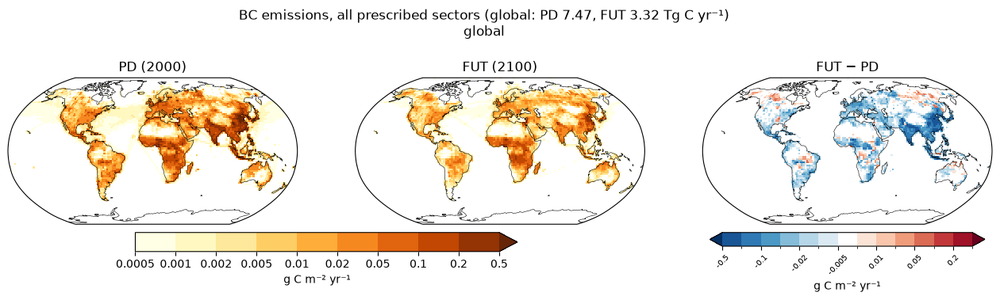

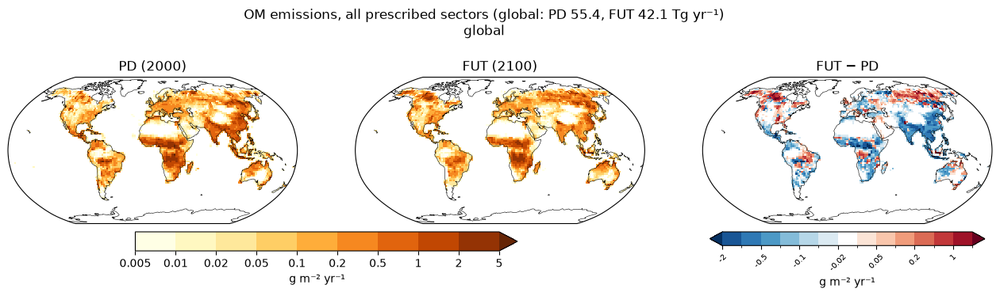

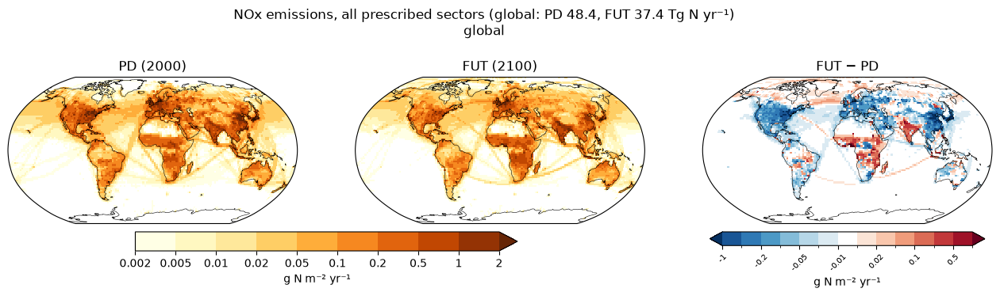

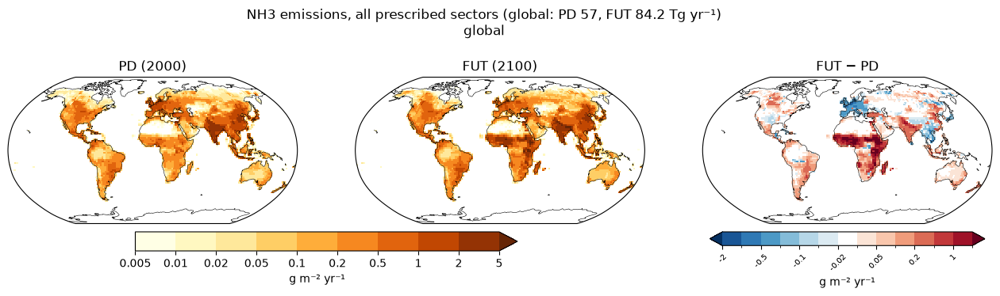

...

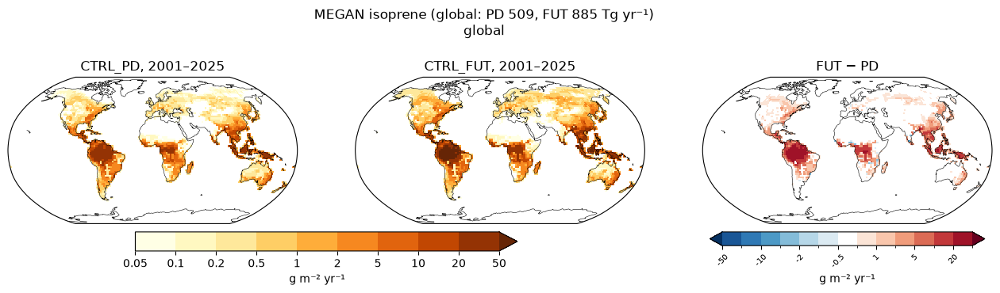

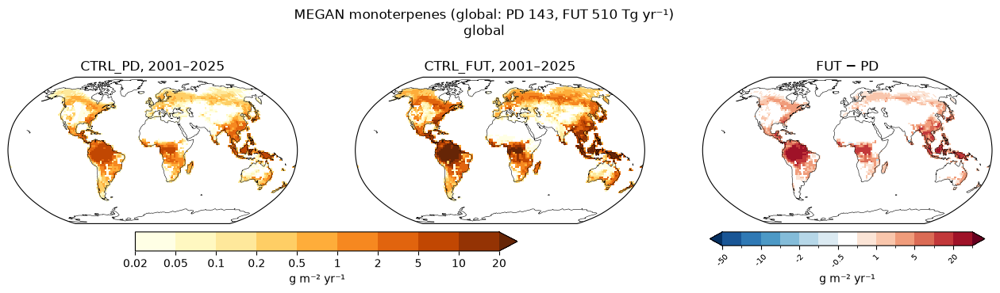

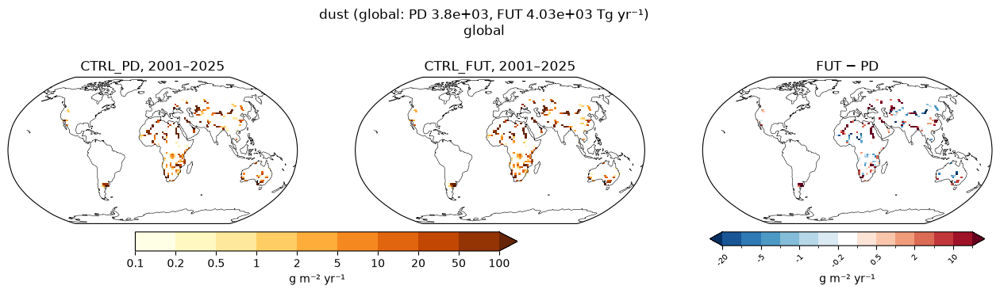

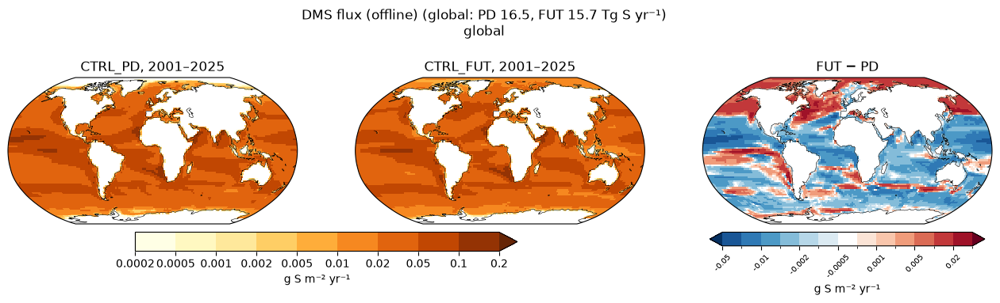

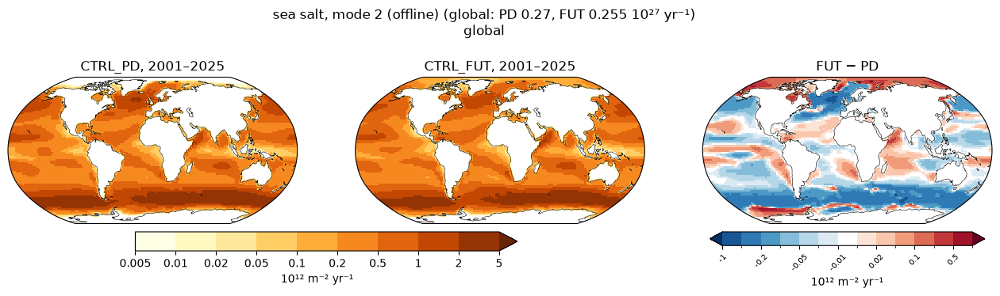

In [17]:
for fn, args, kw in list(APPENDIX):
    fn(*args, region='global', **kw)
